**Image Data Exploration and OCR**

This project aims to classify images as Alcohol or Non-Alcohol based on their text content.

The pipeline combines OCR for text extraction and NLP for classification. The notebook covers data exploration, preprocessing, model development, and performance evaluation.

Run from the repository root using the environment described in `README.md`.

In [95]:
test_mode = False # Set to True to run on a small test dataset, False to run on the full dataset

# Imports

In [96]:
import re
import unicodedata
from collections import Counter, defaultdict
from difflib import SequenceMatcher, get_close_matches
from math import ceil, floor
from pathlib import Path

import cmudict
import easyocr
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
from PIL import Image, ImageOps
from scipy import sparse
from sentence_transformers import SentenceTransformer
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    auc,
    classification_report,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
from xgboost import XGBClassifier


if test_mode:
    DATA_DIR = Path("images_test")
    RESULTS_DIR = Path("results_test")
else:
    DATA_DIR = Path("images")
    RESULTS_DIR = Path("results")

RESULTS_DIR.mkdir(exist_ok=True)
DATA_RESULTS_DIR = RESULTS_DIR / "data"
OCR_RESULTS_DIR = RESULTS_DIR / "ocr"
DATA_RESULTS_DIR.mkdir(exist_ok=True)
OCR_RESULTS_DIR.mkdir(exist_ok=True)

pd.options.display.float_format = "{:,.2f}".format
plt.rcParams.update(
    {"font.size": 16, "axes.titlesize": 20, "axes.labelsize": 18}
)

# Limit CPU threads to avoid excessive overhead on these small images.
torch.set_num_threads(4)

# Data

Use the parent folder as the label: `alcohol` or `non_alcohol`. Load each image to check it is readable and collect its dimensions, format, and file size. Keep file paths rather than all image pixels in memory.

Save dataset metadata, statistics, and sample figures in the `data/` subfolder of the selected results folder.

## Load Dataset

In [97]:
def load_image_dataset(data_dir):
    """Load image paths, folder labels, and basic image metadata.

    Args:
        data_dir (Path): Directory containing alcohol and non_alcohol folders.

    Returns:
        pd.DataFrame: One row per image with its path, label, and metadata.
    """
    records = []
    image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    for label in ("alcohol", "non_alcohol"):
        for image_path in sorted((data_dir / label).iterdir()):
            if image_path.suffix.lower() not in image_extensions:
                continue
            with Image.open(image_path) as image:
                image.load()
                width, height = ImageOps.exif_transpose(image).size
                records.append(
                    {
                        "file_name": image_path.name,
                        "image_path": str(image_path),
                        "label": label,
                        "width": width,
                        "height": height,
                        "format": image.format,
                        "mode": image.mode,
                        "file_size_kb": image_path.stat().st_size / 1024,
                    }
                )

    return pd.DataFrame(records)

In [98]:
dataset = load_image_dataset(DATA_DIR)
display(dataset.sample(10))

,file_name,image_path,label,width,height,format,mode,file_size_kb
785,0253na.jpg,images/non_alcohol/0253na.jpg,non_alcohol,640,480,JPEG,RGB,185.32
114,0124a.jpg,images/alcohol/0124a.jpg,alcohol,640,427,JPEG,RGB,203.38
30,0032a.jpg,images/alcohol/0032a.jpg,alcohol,375,500,JPEG,RGB,88.76
497,3042a.jpg,images/alcohol/3042a.jpg,alcohol,640,480,JPEG,RGB,220.33
136,0148a.jpg,images/alcohol/0148a.jpg,alcohol,612,612,JPEG,RGB,248.24
486,3029a.jpg,images/alcohol/3029a.jpg,alcohol,478,640,JPEG,RGB,124.20
1086,3086na.jpg,images/non_alcohol/3086na.jpg,non_alcohol,640,427,JPEG,RGB,162.04
557,0010na.jpg,images/non_alcohol/0010na.jpg,non_alcohol,500,333,JPEG,RGB,76.97
991,0473na.jpg,images/non_alcohol/0473na.jpg,non_alcohol,640,426,JPEG,RGB,122.24
936,0416na.jpg,images/non_alcohol/0416na.jpg,non_alcohol,375,500,JPEG,RGB,115.62


## Datasets Statistics

Total images: 1,100
Total file size: 138.54 MB


,file_name,image_path,label,width,height,format,mode,file_size_kb
0,0000a.jpg,images/alcohol/0000a.jpg,alcohol,640,427,JPEG,RGB,149.35
1,0001a.jpg,images/alcohol/0001a.jpg,alcohol,314,500,JPEG,RGB,89.23
2,0003a.jpg,images/alcohol/0003a.jpg,alcohol,640,427,JPEG,RGB,201.13
3,0004a.jpg,images/alcohol/0004a.jpg,alcohol,500,438,JPEG,RGB,95.90
4,0005a.jpg,images/alcohol/0005a.jpg,alcohol,640,480,JPEG,RGB,142.84


,image_count,percentage
label,,
alcohol,550,50.00
non_alcohol,550,50.00


,count,mean,std,min,25%,50%,75%,max
width,"1,100.00",573.98,94.99,238.00,500.00,640.00,640.00,640.00
height,"1,100.00",482.82,100.07,180.00,426.00,480.00,512.25,640.00
file_size_kb,"1,100.00",128.97,44.39,14.46,96.80,126.24,154.37,355.79


,,image_count
format,mode,
JPEG,RGB,1100


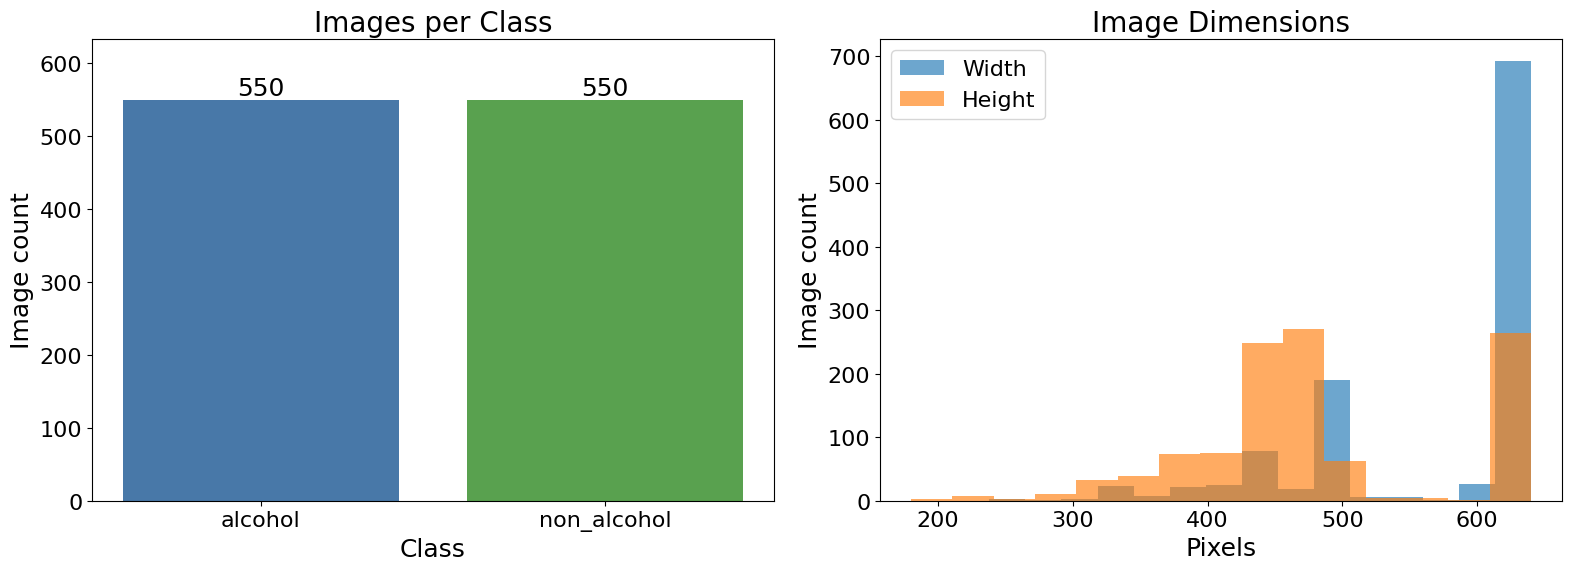

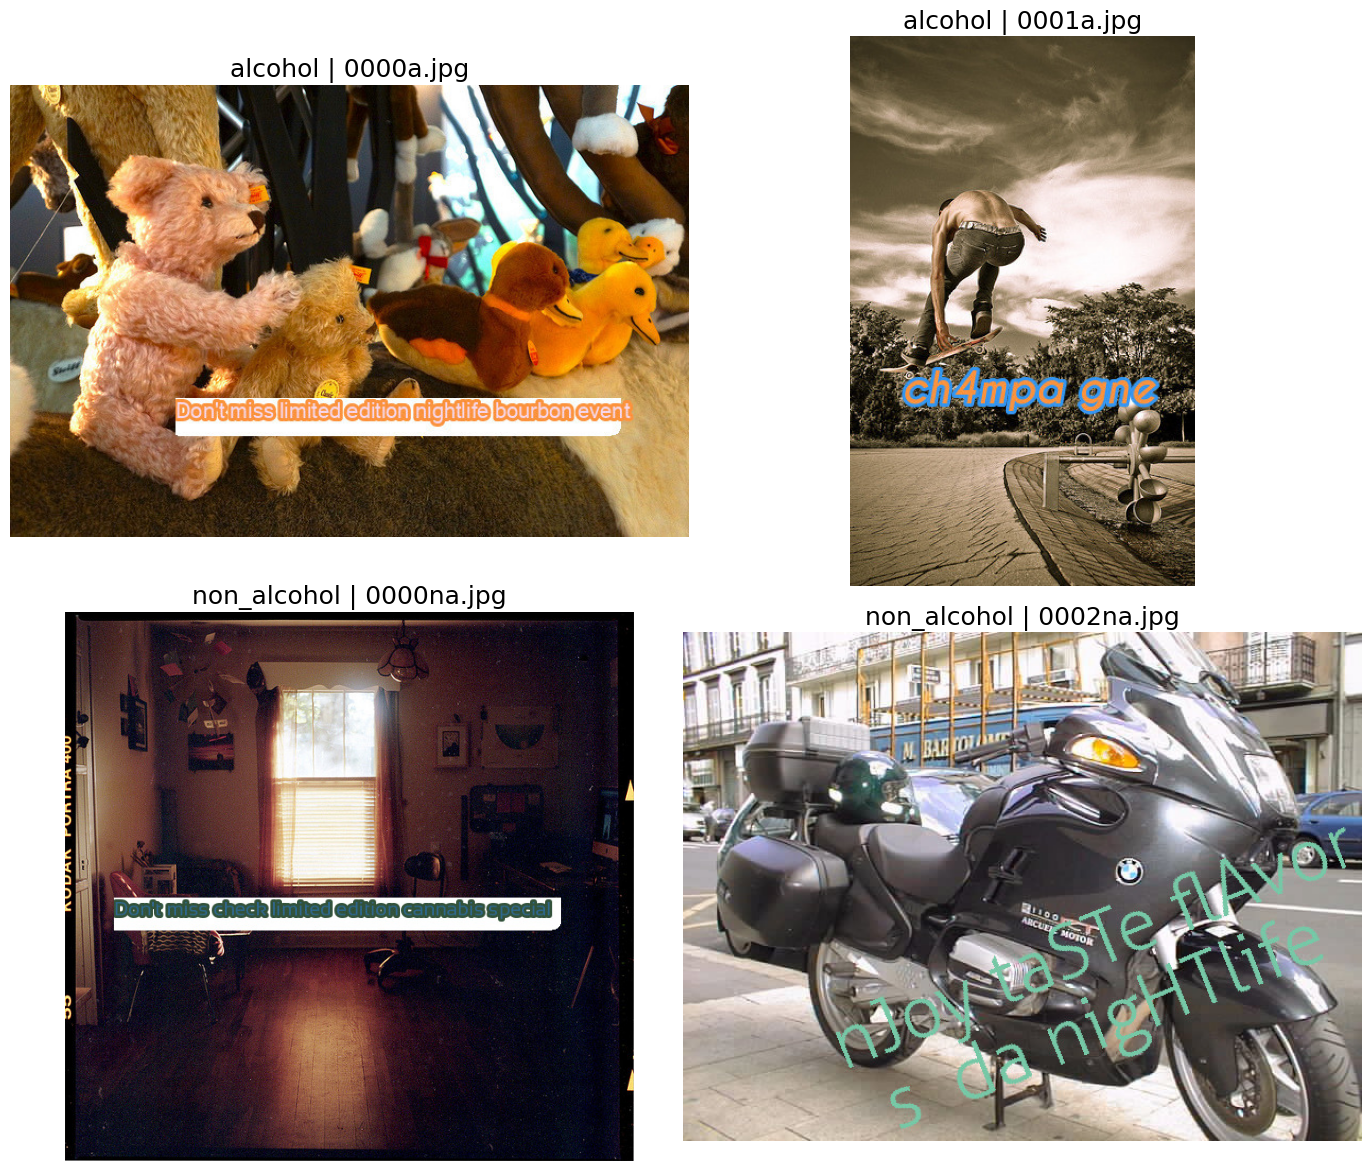

In [99]:
class_summary = dataset.groupby("label").size().rename("image_count").to_frame()
class_summary["percentage"] = class_summary["image_count"] / len(dataset) * 100
image_statistics = dataset[["width", "height", "file_size_kb"]].describe().T

print(f"Total images: {len(dataset):,}")
print(f"Total file size: {dataset['file_size_kb'].sum() / 1024:,.2f} MB")
display(dataset.head())
display(
    class_summary.style.format(
        {"image_count": "{:,.0f}", "percentage": "{:,.2f}"}
    )
)
display(image_statistics)
display(
    dataset.groupby(["format", "mode"]).size().rename("image_count").to_frame()
)

dataset.to_csv(DATA_RESULTS_DIR / "image_metadata.csv", index=False)
class_summary.to_csv(DATA_RESULTS_DIR / "class_summary.csv")
image_statistics.to_csv(DATA_RESULTS_DIR / "image_statistics.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(
    class_summary.index,
    class_summary["image_count"],
    color=["#4878A8", "#59A14F"],
)
axes[0].set(title="Images per Class", xlabel="Class", ylabel="Image count")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
for position, count in enumerate(class_summary["image_count"]):
    axes[0].text(
        position, count, f"{count:,}", ha="center", va="bottom", fontsize=18
    )
axes[0].set_ylim(0, class_summary["image_count"].max() * 1.15)

axes[1].hist(dataset["width"], bins=15, alpha=0.65, label="Width")
axes[1].hist(dataset["height"], bins=15, alpha=0.65, label="Height")
axes[1].set(title="Image Dimensions", xlabel="Pixels", ylabel="Image count")
axes[1].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].legend()
fig.tight_layout()
fig.savefig(
    DATA_RESULTS_DIR / "dataset_statistics.png", dpi=150, bbox_inches="tight"
)
plt.show()

# Show the first two images in each class for a reproducible visual check.
examples = dataset.groupby("label", sort=True).head(2)
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for axis, row in zip(axes.flat, examples.itertuples(index=False)):
    with Image.open(row.image_path) as image:
        axis.imshow(ImageOps.exif_transpose(image).convert("RGB"))
    axis.set_title(f"{row.label} | {row.file_name}", fontsize=18)
    axis.axis("off")
fig.tight_layout()
fig.savefig(DATA_RESULTS_DIR / "sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

# Extract Text

Use [EasyOCR](https://www.jaided.ai/easyocr/documentation/) with English recognition and `gpu=False`. Initialize the reader once. The first extraction downloads pretrained models into `.cache/easyocr/`; later runs reuse them.

Apply EXIF orientation and extract text from the original image. Accept that attempt when at least 80% of its word occurrences are recognized English words and its mean text-box confidence is at least 0.80. Otherwise, mirror the image horizontally and run OCR again. Keep the attempt with the higher mean confidence; ties keep the original. Missing confidence ranks below any valid confidence. Keep the winning text even if it remains below a threshold.

English recognition uses the bundled CMU dictionary plus the editable beverage and brand vocabulary below. For lookup only, lowercase words and normalize apostrophes. Ignore punctuation and purely numeric tokens; mixed letter/number tokens and words outside the vocabulary count as unrecognized. Empty text has an English ratio of zero and missing OCR confidence. Dictionary coverage is an approximation of English quality, not a language detector. No spelling correction or segmentation is applied.

Keep the selected text, word count, text-box count, confidence, and English ratio, together with each attempt's text and scores. Join nonempty text boxes with spaces without assuming a reliable reading order. OCR coverage and confidence describe extraction behavior, not transcription accuracy.

Reuse `OCR_RESULTS_DIR / "ocr_text.csv"` only when it includes all retry fields. Existing CSVs without those fields are refreshed automatically on the next run. To rerun after changing images, thresholds, or vocabulary, remove the saved CSV. Test/full mode uses its own results folder. Rerun the downstream embedding and classification cells to consume the selected text.

Save extracted text, summaries, comparison tables, and figures in the `ocr/` subfolder of the selected results folder.


## OCR

In [100]:
MIN_ENGLISH_RATIO = 0.80
MIN_OCR_CONFIDENCE = 0.80
BEVERAGE_WORDS = {
    "absolut", "bacardi", "budweiser", "heineken",
    "jagermeister", "smirnoff", "matcha", "kombucha",
}
OCR_RETRY_COLUMNS = {
    "english_word_ratio", "flip_attempted", "selected_orientation",
    "original_text", "original_mean_confidence", "original_english_word_ratio",
    "flipped_text", "flipped_mean_confidence", "flipped_english_word_ratio",
}


def load_english_vocabulary(extra_words):
    """Load dictionary words and add beverage and brand names.

    Args:
        extra_words (set[str]): Additional lowercase words accepted as English.

    Returns:
        set[str]: Vocabulary reused across all OCR attempts.
    """
    return set(cmudict.words()) | extra_words


def calculate_english_word_ratio(text, english_words):
    """Measure the fraction of word occurrences recognized by the vocabulary.

    Args:
        text (str): OCR text to evaluate without changing its transcription.
        english_words (set[str]): Lowercase recognized English words.

    Returns:
        float: Recognized-word fraction, or zero when no words are present.
    """
    lookup_text = text.casefold().replace("’", "'").replace("‘", "'")
    tokens = re.findall(r"[^\W_]+(?:'[^\W_]+)*", lookup_text)
    words = [token for token in tokens if not token.isnumeric()]
    if not words:
        return 0.0
    recognized = sum(
        word.isascii()
        and not any(character.isdigit() for character in word)
        and word in english_words
        for word in words
    )
    return recognized / len(words)


def create_ocr_reader(model_dir):
    """Initialize an English EasyOCR reader for CPU-only execution.

    Args:
        model_dir (Path): Local directory for downloaded OCR model weights.

    Returns:
        easyocr.Reader: Reader shared across all images.
    """
    return easyocr.Reader(
        ["en"],
        gpu=False,
        model_storage_directory=str(model_dir),
        user_network_directory=str(model_dir / "user_network"),
        verbose=True,
    )


def summarize_ocr_attempt(detections, english_words):
    """Summarize nonempty detections from one OCR attempt.

    Args:
        detections (list): EasyOCR bounding-box, text, and confidence tuples.
        english_words (set[str]): Recognized English words.

    Returns:
        dict: Text, counts, mean confidence, and English-word ratio.
    """
    text_parts = [text for _, text, _ in detections if text.strip()]
    confidences = [
        float(confidence)
        for _, text, confidence in detections
        if text.strip()
    ]
    extracted_text = " ".join(text_parts)
    return {
        "extracted_text": extracted_text,
        "word_count": len(extracted_text.split()),
        "text_box_count": len(text_parts),
        "mean_confidence": np.mean(confidences) if confidences else np.nan,
        "english_word_ratio": calculate_english_word_ratio(
            extracted_text, english_words
        ),
    }


def extract_image_text(
    dataset, reader, english_words, min_english_ratio=0.80, min_confidence=0.80
):
    """Extract text and retry a horizontal flip when quality is below threshold.

    Args:
        dataset (pd.DataFrame): Image metadata including image_path.
        reader (easyocr.Reader): Initialized OCR reader.
        english_words (set[str]): Recognized English words.
        min_english_ratio (float): Minimum ratio to accept the original attempt.
        min_confidence (float): Minimum confidence to accept the original attempt.

    Returns:
        pd.DataFrame: Metadata and selected OCR results in input row order,
            including original and flipped attempt scores and text.
    """
    records = []
    for row in tqdm(
        dataset.itertuples(index=False), total=len(dataset), desc="OCR"
    ):
        with Image.open(row.image_path) as image:
            oriented_image = ImageOps.exif_transpose(image).convert("RGB")
        original = summarize_ocr_attempt(
            reader.readtext(np.array(oriented_image), detail=1, paragraph=False),
            english_words,
        )
        flip_attempted = not (
            original["english_word_ratio"] >= min_english_ratio
            and original["mean_confidence"] >= min_confidence
        )
        selected = original
        selected_orientation = "original"
        flipped = None
        if flip_attempted:
            flipped = summarize_ocr_attempt(
                reader.readtext(
                    np.array(ImageOps.mirror(oriented_image)),
                    detail=1,
                    paragraph=False,
                ),
                english_words,
            )
            # Empty attempts cannot beat valid confidence; ties keep the original.
            original_score = original["mean_confidence"]
            if pd.isna(original_score):
                original_score = -1.0
            if flipped["mean_confidence"] > original_score:
                selected = flipped
                selected_orientation = "flipped"
        records.append(
            {
                **selected,
                "flip_attempted": flip_attempted,
                "selected_orientation": selected_orientation,
                "original_text": original["extracted_text"],
                "original_mean_confidence": original["mean_confidence"],
                "original_english_word_ratio": original["english_word_ratio"],
                "flipped_text": flipped["extracted_text"] if flipped else "",
                "flipped_mean_confidence": (
                    flipped["mean_confidence"] if flipped else np.nan
                ),
                "flipped_english_word_ratio": (
                    flipped["english_word_ratio"] if flipped else np.nan
                ),
            }
        )

    return pd.concat(
        [dataset.reset_index(drop=True), pd.DataFrame(records)], axis=1
    )


def load_or_extract_ocr(dataset, results_path, model_dir, english_words):
    """Reuse OCR results with retry fields, or extract and save updated results.

    Args:
        dataset (pd.DataFrame): Image metadata for OCR extraction.
        results_path (Path): Selected test/full OCR CSV path.
        model_dir (Path): Directory containing EasyOCR model weights.
        english_words (set[str]): Recognized English words.

    Returns:
        pd.DataFrame: Cached or newly extracted OCR results.
    """
    if results_path.is_file():
        cached_results = pd.read_csv(
            results_path,
            dtype={
                column: str
                for column in ("extracted_text", "original_text", "flipped_text")
            },
            keep_default_na=False,
            na_values={
                column: [""]
                for column in (
                    "mean_confidence", "original_mean_confidence",
                    "flipped_mean_confidence", "flipped_english_word_ratio",
                )
            },
        )
        if OCR_RETRY_COLUMNS.issubset(cached_results.columns):
            print(f"Loaded OCR results for {len(cached_results):,} images")
            return cached_results
        print("Saved OCR results lack retry fields; refreshing the CSV.")

    reader = create_ocr_reader(model_dir)
    results = extract_image_text(
        dataset, reader, english_words,
        min_english_ratio=MIN_ENGLISH_RATIO,
        min_confidence=MIN_OCR_CONFIDENCE,
    )
    results.to_csv(results_path, index=False)
    print(f"Saved OCR results to {results_path}")
    return results


In [101]:
english_words = load_english_vocabulary(BEVERAGE_WORDS)
ocr_results_path = OCR_RESULTS_DIR / "ocr_text.csv"
ocr_results = load_or_extract_ocr(
    dataset, ocr_results_path, Path(".cache") / "easyocr", english_words
)


Using CPU. Note: This module is much faster with a GPU.


OCR:   0%|          | 0/1100 [00:00<?, ?it/s]

Saved OCR results to results/ocr/ocr_text.csv


Images with extracted text: 1,078 / 1,100


,image_count,images_with_text,mean_word_count,mean_confidence,mean_english_word_ratio,flip_attempts,images_without_text,text_coverage_percent
label,,,,,,,,
alcohol,550,537,4.44,0.57,0.53,458,13,97.64
non_alcohol,550,541,4.62,0.57,0.49,477,9,98.36


,file_name,label,extracted_text,word_count,mean_confidence
0,0000a.jpg,alcohol,Donlmisslimitededitionnighilifebourbonevent,1,0.49
1,0001a.jpg,alcohol,chAnpa 013,2,0.31
2,0003a.jpg,alcohol,Dont Ims9 0ob now Te3TEJEE3Z7E pemim,6,0.35
550,0000na.jpg,non_alcohol,) { 3 Dontmiescheclumiededitoncannab 3cpeca],5,0.54
551,0002na.jpg,non_alcohol,5 Y flAvor/ LaSTe nighTlite nsey,6,0.38
552,0005na.jpg,non_alcohol,coffee imported,2,0.83


Images without detected text (up to five examples):


,file_name,label
24,0026a.jpg,alcohol
30,0032a.jpg,alcohol
52,0057a.jpg,alcohol
77,0085a.jpg,alcohol
101,0110a.jpg,alcohol


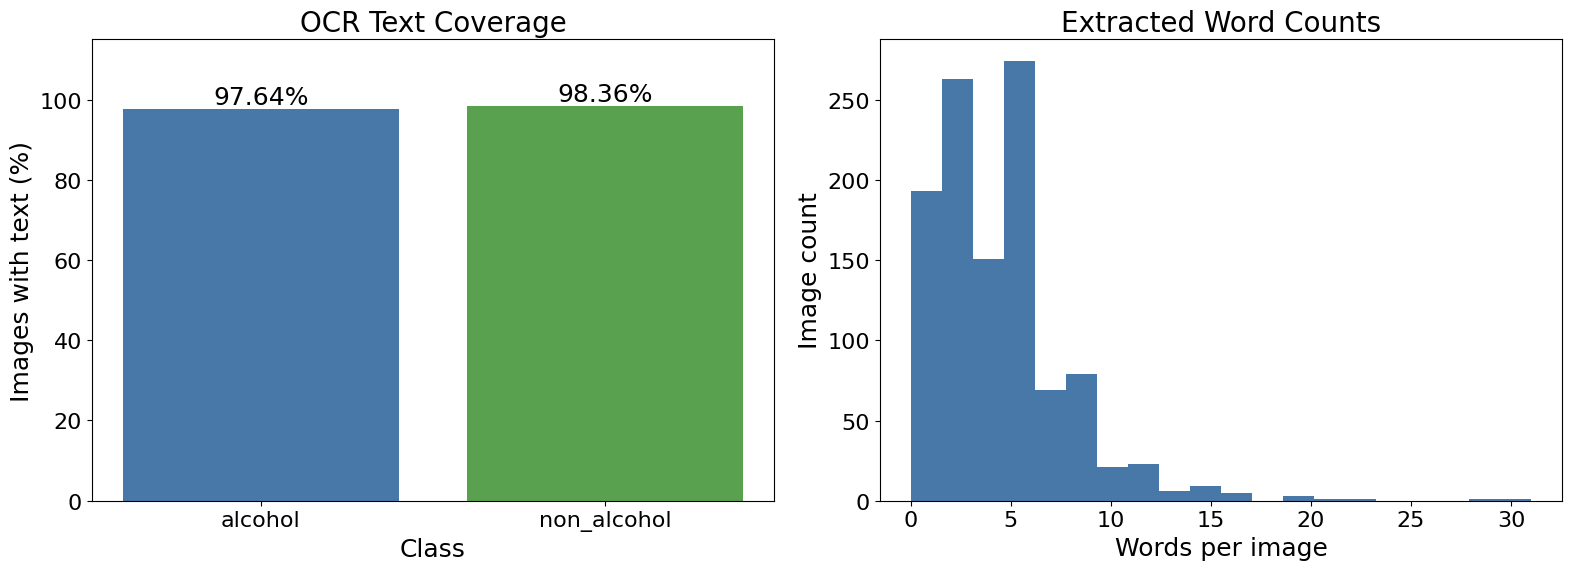

Horizontal-flip retry results:


,images,flip_attempts,flipped_selections,remaining_below_threshold
0,"1,100",935,247,908


,file_name,label,flip_attempted,selected_orientation,original_text,original_english_word_ratio,original_mean_confidence,flipped_text,flipped_english_word_ratio,flipped_mean_confidence,extracted_text,english_word_ratio,mean_confidence
0,0000a.jpg,alcohol,True,original,Donlmisslimitededitionnighilifebourbonevent,0.00%,49.19%,tnevanodwodetilidginnoilibabsiinilezimfnod,0.00%,16.87%,Donlmisslimitededitionnighilifebourbonevent,0.00%,49.19%
1,0001a.jpg,alcohol,True,original,chAnpa 013,0.00%,31.36%,Mo Damais,50.00%,12.43%,chAnpa 013,0.00%,31.36%
2,0003a.jpg,alcohol,True,original,Dont Ims9 0ob now Te3TEJEE3Z7E pemim,16.67%,35.34%,Cnco ezmm 6d Iwon Dane Jdd Mmmen,14.29%,25.30%,Dont Ims9 0ob now Te3TEJEE3Z7E pemim,16.67%,35.34%
3,0004a.jpg,alcohol,True,original,QHAMAVAWAX 'DMAV aed,0.00%,33.11%,KAWANANAIO Jaatan OEdeDurer Naxdl Jear,0.00%,7.60%,QHAMAVAWAX 'DMAV aed,0.00%,33.11%
4,0005a.jpg,alcohol,True,original,Douftmisslimited editionlited editiom port imported,40.00%,57.94%,bstialeeiflod bafoquisuoquofibobsfiallaofibs,0.00%,9.25%,Douftmisslimited editionlited editiom port imported,40.00%,57.94%
5,0006a.jpg,alcohol,True,original,Tevent nSenve budwelser-favoR;,25.00%,32.61%,Hovsl z9el9Wbud p1s2an novant,0.00%,2.21%,Tevent nSenve budwelser-favoR;,25.00%,32.61%
7,0008a.jpg,alcohol,True,original,ont miss taste specal event port,66.67%,92.53%,16 8*1m 9136] poq? jnsv9 Jioq,0.00%,30.69%,ont miss taste specal event port,66.67%,92.53%
8,0009a.jpg,alcohol,True,original,Get eadyfor smoothwhbhoypaty,33.33%,45.39%,8) koqretwioonervooo,0.00%,10.19%,Get eadyfor smoothwhbhoypaty,33.33%,45.39%
9,0010a.jpg,alcohol,True,original,Don t miss LRZD HUW chArnaCaE gheck,42.86%,41.11%,"eeim Jnoq WoIn @Eie, 45365 HADeccaAd5",0.00%,9.47%,Don t miss LRZD HUW chArnaCaE gheck,42.86%,41.11%
10,0011a.jpg,alcohol,True,original,miss party Don't partytequila,75.00%,98.48%,zzim vtinq f'noa pliupotvtIpq,0.00%,44.69%,miss party Don't partytequila,75.00%,98.48%


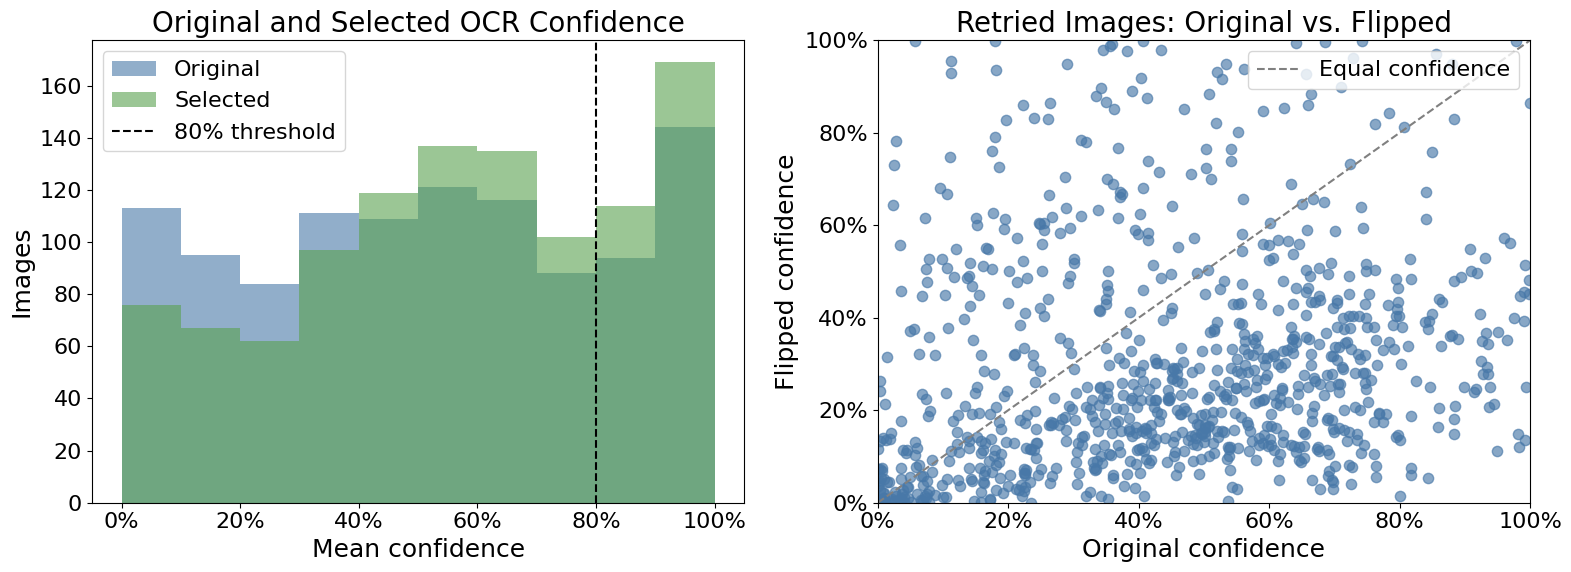

In [102]:
ocr_summary = (
    ocr_results.assign(has_text=ocr_results["word_count"].gt(0))
    .groupby("label")
    .agg(
        image_count=("file_name", "size"),
        images_with_text=("has_text", "sum"),
        mean_word_count=("word_count", "mean"),
        mean_confidence=("mean_confidence", "mean"),
        mean_english_word_ratio=("english_word_ratio", "mean"),
        flip_attempts=("flip_attempted", "sum"),
    )
)
ocr_summary["images_without_text"] = (
    ocr_summary["image_count"] - ocr_summary["images_with_text"]
)
ocr_summary["text_coverage_percent"] = (
    ocr_summary["images_with_text"] / ocr_summary["image_count"] * 100
)
ocr_summary.to_csv(OCR_RESULTS_DIR / "ocr_summary.csv")

print(
    f"Images with extracted text: {ocr_results['word_count'].gt(0).sum():,}"
    f" / {len(ocr_results):,}"
)
display(ocr_summary)
display(
    ocr_results.groupby("label", sort=True)
    .head(3)[
        [
            "file_name",
            "label",
            "extracted_text",
            "word_count",
            "mean_confidence",
        ]
    ]
    .style.format(
        {"word_count": "{:,.0f}", "mean_confidence": "{:,.2f}"}, na_rep="N/A"
    )
)
print("Images without detected text (up to five examples):")
display(
    ocr_results.loc[
        ocr_results["word_count"].eq(0), ["file_name", "label"]
    ].head()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].bar(
    ocr_summary.index,
    ocr_summary["text_coverage_percent"],
    color=["#4878A8", "#59A14F"],
)
axes[0].set(
    title="OCR Text Coverage",
    xlabel="Class",
    ylabel="Images with text (%)",
    ylim=(0, 115),
)
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
for position, coverage in enumerate(ocr_summary["text_coverage_percent"]):
    axes[0].text(
        position,
        coverage,
        f"{coverage:,.2f}%",
        ha="center",
        va="bottom",
        fontsize=18,
    )

axes[1].hist(ocr_results["word_count"], bins=20, color="#4878A8")
axes[1].set(
    title="Extracted Word Counts",
    xlabel="Words per image",
    ylabel="Image count",
)
axes[1].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
fig.tight_layout()
fig.savefig(OCR_RESULTS_DIR / "ocr_statistics.png", dpi=150, bbox_inches="tight")
plt.show()

meets_thresholds = (
    ocr_results["english_word_ratio"].ge(MIN_ENGLISH_RATIO)
    & ocr_results["mean_confidence"].ge(MIN_OCR_CONFIDENCE)
)
retry_summary = pd.DataFrame(
    {
        "images": [len(ocr_results)],
        "flip_attempts": [ocr_results["flip_attempted"].sum()],
        "flipped_selections": [ocr_results["selected_orientation"].eq("flipped").sum()],
        "remaining_below_threshold": [(~meets_thresholds).sum()],
    }
)
comparison_columns = [
    "file_name", "label", "flip_attempted", "selected_orientation",
    "original_text", "original_english_word_ratio", "original_mean_confidence",
    "flipped_text", "flipped_english_word_ratio", "flipped_mean_confidence",
    "extracted_text", "english_word_ratio", "mean_confidence",
]
ocr_comparison = ocr_results[comparison_columns]
retry_summary.to_csv(OCR_RESULTS_DIR / "ocr_retry_summary.csv", index=False)
ocr_comparison.to_csv(OCR_RESULTS_DIR / "ocr_attempt_comparison.csv", index=False)

print("Horizontal-flip retry results:")
display(retry_summary.style.format("{:,.0f}"))
display(
    ocr_comparison.loc[ocr_comparison["flip_attempted"]].head(10).style.format(
        {
            column: "{:,.2%}"
            for column in comparison_columns
            if "confidence" in column or "ratio" in column
        },
        na_rep="N/A",
    )
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for column, label, color in (
    ("original_mean_confidence", "Original", "#4878A8"),
    ("mean_confidence", "Selected", "#59A14F"),
):
    axes[0].hist(
        ocr_results[column].dropna(), bins=np.linspace(0, 1, 11),
        alpha=0.60, label=label, color=color,
    )
axes[0].axvline(
    MIN_OCR_CONFIDENCE, linestyle="--", color="black", label="80% threshold"
)
axes[0].set(
    title="Original and Selected OCR Confidence",
    xlabel="Mean confidence", ylabel="Images",
)
axes[0].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0%}"))
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[0].legend()

retried = ocr_results.loc[ocr_results["flip_attempted"]]
axes[1].scatter(
    retried["original_mean_confidence"], retried["flipped_mean_confidence"],
    s=55, alpha=0.65, color="#4878A8",
)
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Equal confidence")
axes[1].set(
    title="Retried Images: Original vs. Flipped", xlabel="Original confidence",
    ylabel="Flipped confidence", xlim=(0, 1), ylim=(0, 1),
)
axes[1].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0%}"))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0%}"))
axes[1].legend()
fig.tight_layout()
fig.savefig(OCR_RESULTS_DIR / "ocr_retry_confidence.png", dpi=150, bbox_inches="tight")
plt.show()


# Clean Text

Normalize the selected OCR text with Unicode NFKC, lowercase, normalized apostrophes, and single spaces. Preserve the raw `extracted_text` and save the result in `cleaned_text`.

Keep recognized English words and alcohol-brand and drink tokens unchanged. For unknown words containing letters and digits, first try the configured number-to-letter mapping and accept an exact vocabulary match. Otherwise, compare both the original normalized token and the converted candidate against English words and brand tokens. Use `SequenceMatcher` similarity of at least MIN_WORD_SIMILARITY; different target words tied for the highest score leave the original token unchanged. Preserve punctuation, standalone numbers, and unmatched tokens. Multiword brands contribute their component words; merged OCR words are not segmented.

The English dictionary and OCR retry thresholds come from the earlier OCR section.
Cleaning is recomputed each run, independently of the OCR cache. Both embedding types and classification consume `cleaned_text` when their cells are rerun.


In [103]:
from alcohol_lists import ALCOHOL_BRANDS, ALCOHOL_DRINKS

MIN_WORD_SIMILARITY = 0.90
NUMBER_TO_LETTER = {
    "0": "o",
    "1": "i",
    "2": "z",
    "3": "e",
    "4": "a",
    "5": "s",
    "6": "g",
    "7": "t",
    "8": "b",
    "9": "g",
}
ALCOHOL_TERMS = set(ALCOHOL_BRANDS) | set(ALCOHOL_DRINKS)


In [104]:
def normalize_ocr_text(text):
    """Normalize Unicode, case, apostrophes, and spacing in OCR text.

    Args:
        text (str): Raw OCR text, possibly missing.

    Returns:
        str: Normalized text, or an empty string for missing values.
    """
    if pd.isna(text):
        return ""
    text = unicodedata.normalize("NFKC", str(text)).lower()
    text = text.replace("’", "'").replace("‘", "'")
    return re.sub(r"\s+", " ", text).strip()


def build_cleaning_vocabulary(english_words, alcohol_terms):
    """Combine English words and component words from alcohol terms.

    Args:
        english_words (set[str]): Vocabulary loaded in the OCR section.
        alcohol_terms (set[str]): Imported alcohol-brand and drink terms.

    Returns:
        tuple: Combined vocabulary and candidate words grouped by length.
    """
    vocabulary = set(english_words)
    for term in alcohol_terms:
        vocabulary.update(
            re.findall(r"[^\W_]+(?:'[^\W_]+)*", normalize_ocr_text(term))
        )
    word_groups = defaultdict(list)
    for word in sorted(vocabulary):
        word_groups[len(word)].append(word)
    return vocabulary, word_groups


def correct_ocr_word(
    word, vocabulary, word_groups, number_translation, min_similarity
):
    """Correct an unknown token using digit conversion and vocabulary similarity.

    Args:
        word (str): Normalized word token.
        vocabulary (set[str]): Recognized English and alcohol-term tokens.
        word_groups (dict): Candidate vocabulary grouped by word length.
        number_translation (dict): Translation table created with str.maketrans.
        min_similarity (float): Inclusive minimum SequenceMatcher similarity.

    Returns:
        str: Unique best correction, or the input token if no match or a tie.
    """
    if word in vocabulary or not any(character.isalpha() for character in word):
        return word

    candidates = {word}
    if any(character.isdigit() for character in word):
        converted = word.translate(number_translation)
        if converted in vocabulary:
            return converted
        candidates.add(converted)

    best_score = min_similarity
    best_matches = set()
    for candidate in sorted(candidates):
        # Similarity cannot exceed 2 * min(lengths) / sum(lengths).
        min_length = ceil(len(candidate) * min_similarity / (2 - min_similarity))
        max_length = floor(len(candidate) * (2 - min_similarity) / min_similarity)
        possible_words = [
            target
            for length in range(min_length, max_length + 1)
            for target in word_groups.get(length, [])
        ]
        # Two results suffice to detect a tie between different target words.
        matches = get_close_matches(
            candidate, possible_words, n=2, cutoff=min_similarity
        )
        for target in matches:
            score = SequenceMatcher(None, target, candidate).ratio()
            if score > best_score:
                best_score = score
                best_matches = {target}
            elif score == best_score:
                best_matches.add(target)

    if len(best_matches) == 1:
        return next(iter(best_matches))
    return word


def clean_ocr_results(
    results, english_words, alcohol_terms, number_to_letter, min_similarity=0.90
):
    """Add cleaned OCR text and count each applied token correction.

    Args:
        results (pd.DataFrame): OCR results containing extracted_text.
        english_words (set[str]): Vocabulary loaded once in the OCR section.
        alcohol_terms (set[str]): Additional alcohol-brand and drink terms.
        number_to_letter (dict[str, str]): Editable digit-to-letter substitutions.
        min_similarity (float): Inclusive correction threshold in the range (0, 1].

    Returns:
        tuple: Copy of OCR results with cleaned_text, and a correction-count table.
    """
    vocabulary, word_groups = build_cleaning_vocabulary(english_words, alcohol_terms)
    number_translation = str.maketrans(number_to_letter)
    correction_cache = {}
    correction_counts = Counter()

    def replace_word(match):
        """Replace one token while recording every corrected occurrence.

        Args:
            match (re.Match): Token matched within normalized OCR text.

        Returns:
            str: Corrected token or its unchanged normalized form.
        """
        word = match.group()
        if word not in correction_cache:
            correction_cache[word] = correct_ocr_word(
                word, vocabulary, word_groups, number_translation, min_similarity
            )
        corrected = correction_cache[word]
        if corrected != word:
            correction_counts[(word, corrected)] += 1
        return corrected

    cleaned_results = results.copy()
    normalized_texts = results["extracted_text"].map(normalize_ocr_text)
    word_pattern = re.compile(r"[^\W_]+(?:'[^\W_]+)*")
    cleaned_results["cleaned_text"] = normalized_texts.map(
        lambda text: word_pattern.sub(replace_word, text)
    )
    corrections = pd.DataFrame(
        [
            {
                "original_token": original,
                "corrected_token": corrected,
                "occurrences": count,
            }
            for (original, corrected), count in sorted(
                correction_counts.items(), key=lambda item: (-item[1], item[0])
            )
        ],
        columns=["original_token", "corrected_token", "occurrences"],
    )
    return cleaned_results, corrections


In [105]:
ocr_results, cleaning_corrections = clean_ocr_results(
    ocr_results,
    english_words,
    ALCOHOL_TERMS,
    NUMBER_TO_LETTER,
    min_similarity=MIN_WORD_SIMILARITY,
)
ocr_results.to_csv(OCR_RESULTS_DIR / "ocr_text_cleaned.csv", index=False)

display(ocr_results.head(10))
display(cleaning_corrections.head(10))

,file_name,image_path,label,width,height,format,mode,file_size_kb,extracted_text,word_count,...,english_word_ratio,flip_attempted,selected_orientation,original_text,original_mean_confidence,original_english_word_ratio,flipped_text,flipped_mean_confidence,flipped_english_word_ratio,cleaned_text
0,0000a.jpg,images/alcohol/0000a.jpg,alcohol,640,427,JPEG,RGB,149.35,Donlmisslimitededitionnighilifebourbonevent,1,...,0.00,True,original,Donlmisslimitededitionnighilifebourbonevent,0.49,0.00,tnevanodwodetilidginnoilibabsiinilezimfnod,0.17,0.00,donlmisslimitededitionnighilifebourbonevent
1,0001a.jpg,images/alcohol/0001a.jpg,alcohol,314,500,JPEG,RGB,89.23,chAnpa 013,2,...,0.00,True,original,chAnpa 013,0.31,0.00,Mo Damais,0.12,0.50,chanpa 013
2,0003a.jpg,images/alcohol/0003a.jpg,alcohol,640,427,JPEG,RGB,201.13,Dont Ims9 0ob now Te3TEJEE3Z7E pemim,6,...,0.17,True,original,Dont Ims9 0ob now Te3TEJEE3Z7E pemim,0.35,0.17,Cnco ezmm 6d Iwon Dane Jdd Mmmen,0.25,0.14,dont ims9 0ob now te3tejee3z7e pemim
3,0004a.jpg,images/alcohol/0004a.jpg,alcohol,500,438,JPEG,RGB,95.90,QHAMAVAWAX 'DMAV aed,3,...,0.00,True,original,QHAMAVAWAX 'DMAV aed,0.33,0.00,KAWANANAIO Jaatan OEdeDurer Naxdl Jear,0.08,0.00,qhamavawax 'dmav aed
4,0005a.jpg,images/alcohol/0005a.jpg,alcohol,640,480,JPEG,RGB,142.84,Douftmisslimited editionlited editiom port imp...,5,...,0.40,True,original,Douftmisslimited editionlited editiom port imp...,0.58,0.40,bstialeeiflod bafoquisuoquofibobsfiallaofibs,0.09,0.00,douftmisslimited editionlited editiom port imp...
5,0006a.jpg,images/alcohol/0006a.jpg,alcohol,640,480,JPEG,RGB,117.32,Tevent nSenve budwelser-favoR;,3,...,0.25,True,original,Tevent nSenve budwelser-favoR;,0.33,0.25,Hovsl z9el9Wbud p1s2an novant,0.02,0.00,event nsenve budwelser-favor;
6,0007a.jpg,images/alcohol/0007a.jpg,alcohol,640,246,JPEG,RGB,88.26,Try taste lager,3,...,1.00,False,original,Try taste lager,0.82,1.00,,NaN,NaN,try taste lager
7,0008a.jpg,images/alcohol/0008a.jpg,alcohol,640,427,JPEG,RGB,149.64,ont miss taste specal event port,6,...,0.67,True,original,ont miss taste specal event port,0.93,0.67,16 8*1m 9136] poq? jnsv9 Jioq,0.31,0.00,ont miss taste special event port
8,0009a.jpg,images/alcohol/0009a.jpg,alcohol,479,640,JPEG,RGB,124.20,Get eadyfor smoothwhbhoypaty,3,...,0.33,True,original,Get eadyfor smoothwhbhoypaty,0.45,0.33,8) koqretwioonervooo,0.10,0.00,get eadyfor smoothwhbhoypaty
9,0010a.jpg,images/alcohol/0010a.jpg,alcohol,640,289,JPEG,RGB,86.13,Don t miss LRZD HUW chArnaCaE gheck,7,...,0.43,True,original,Don t miss LRZD HUW chArnaCaE gheck,0.41,0.43,"eeim Jnoq WoIn @Eie, 45365 HADeccaAd5",0.09,0.00,don t miss lrzd huw charnacae gheck


,original_token,corrected_token,occurrences
0,lenergy,energy,4
1,icheck,check,3
2,ispecial,special,3
3,rready,ready,3
4,teady,steady,3
5,0y,oy,2
6,3r,er,2
7,3t,et,2
8,7aste,taste,2
9,boubon,bourbon,2


,images,changed_images,corrected_tokens,unique_corrections,empty_cleaned_texts
0,"1,100",871,282,255,22


Changed images, including normalization-only changes:


,file_name,label,extracted_text,cleaned_text
0,0000a.jpg,alcohol,Donlmisslimitededitionnighilifebourbonevent,donlmisslimitededitionnighilifebourbonevent
1,0001a.jpg,alcohol,chAnpa 013,chanpa 013
2,0003a.jpg,alcohol,Dont Ims9 0ob now Te3TEJEE3Z7E pemim,dont ims9 0ob now te3tejee3z7e pemim
3,0004a.jpg,alcohol,QHAMAVAWAX 'DMAV aed,qhamavawax 'dmav aed
4,0005a.jpg,alcohol,Douftmisslimited editionlited editiom port imp...,douftmisslimited editionlited editiom port imp...
5,0006a.jpg,alcohol,Tevent nSenve budwelser-favoR;,event nsenve budwelser-favor;
6,0007a.jpg,alcohol,Try taste lager,try taste lager
7,0008a.jpg,alcohol,ont miss taste specal event port,ont miss taste special event port
8,0009a.jpg,alcohol,Get eadyfor smoothwhbhoypaty,get eadyfor smoothwhbhoypaty
9,0010a.jpg,alcohol,Don t miss LRZD HUW chArnaCaE gheck,don t miss lrzd huw charnacae gheck


,original_token,corrected_token,occurrences
0,lenergy,energy,4
1,icheck,check,3
2,ispecial,special,3
3,rready,ready,3
4,teady,steady,3
5,0y,oy,2
6,3r,er,2
7,3t,et,2
8,7aste,taste,2
9,boubon,bourbon,2


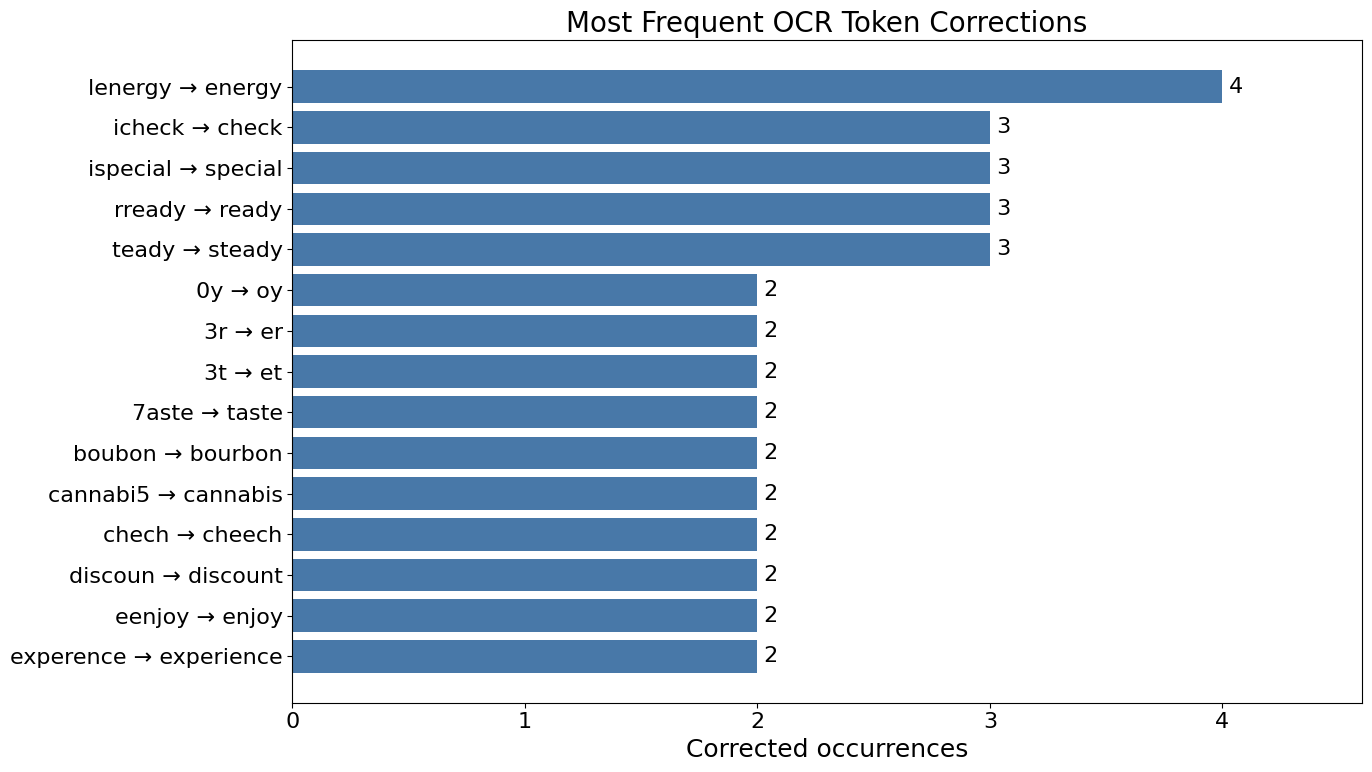

In [106]:
changed_text = (
    ocr_results["extracted_text"].fillna("").astype(str)
    != ocr_results["cleaned_text"]
)
cleaning_summary = pd.DataFrame(
    {
        "images": [len(ocr_results)],
        "changed_images": [changed_text.sum()],
        "corrected_tokens": [cleaning_corrections["occurrences"].sum()],
        "unique_corrections": [len(cleaning_corrections)],
        "empty_cleaned_texts": [ocr_results["cleaned_text"].eq("").sum()],
    }
)
cleaning_summary.to_csv(OCR_RESULTS_DIR / "text_cleaning_summary.csv", index=False)
cleaning_corrections.to_csv(
    OCR_RESULTS_DIR / "text_cleaning_corrections.csv", index=False
)

display(cleaning_summary.style.format("{:,.0f}"))
print("Changed images, including normalization-only changes:")
display(
    ocr_results.loc[
        changed_text, ["file_name", "label", "extracted_text", "cleaned_text"]
    ].head(10)
)
display(cleaning_corrections.head(15).style.format({"occurrences": "{:,.0f}"}))

fig, axis = plt.subplots(figsize=(14, 8))
top_corrections = cleaning_corrections.head(15)
if top_corrections.empty:
    axis.text(
        0.5, 0.5, "No token corrections",
        ha="center", va="center", transform=axis.transAxes,
    )
else:
    correction_labels = (
        top_corrections["original_token"] + " → " + top_corrections["corrected_token"]
    )
    axis.barh(correction_labels, top_corrections["occurrences"], color="#4878A8")
    axis.invert_yaxis()
    for position, count in enumerate(top_corrections["occurrences"]):
        axis.text(count, position, f" {count:,}", va="center", fontsize=16)
    axis.set_xlim(0, top_corrections["occurrences"].max() * 1.15)
axis.set(title="Most Frequent OCR Token Corrections", xlabel="Corrected occurrences")
axis.xaxis.set_major_locator(MaxNLocator(integer=True))
axis.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
fig.tight_layout()
fig.savefig(
    OCR_RESULTS_DIR / "text_cleaning_corrections.png", dpi=150, bbox_inches="tight"
)
plt.show()

# Text Embedding

Convert `cleaned_text` into one feature vector per image using character TF-IDF and MiniLM. Keep both raw and cleaned text in the saved row metadata.


In [107]:
EMBEDDING_RESULTS_DIR = RESULTS_DIR / "embeddings"
TFIDF_RESULTS_DIR = EMBEDDING_RESULTS_DIR / "tfidf"
BERT_RESULTS_DIR = EMBEDDING_RESULTS_DIR / "bert"
TFIDF_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
BERT_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

In [108]:
embedding_texts = ocr_results["cleaned_text"].reset_index(drop=True)
embedding_metadata = ocr_results[
    ["file_name", "image_path", "label", "extracted_text", "cleaned_text"]
].reset_index(drop=True)
embedding_metadata.insert(0, "embedding_row", np.arange(len(embedding_texts)))
embedding_metadata["has_text"] = embedding_texts.ne("")

embedding_metadata.to_csv(
    EMBEDDING_RESULTS_DIR / "embedding_metadata.csv", index=False
)


## TF-IDF

Use [character TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html) with 3–5-character fragments within word boundaries.  
This keeps fragments inside OCR words that lost their spaces and provides a simple representation of partially recognized terms.  
Empty text produces a zero vector.

In [109]:
def create_tfidf_embeddings(texts, max_features=5000):
    """Fit character TF-IDF features to the supplied OCR text.

    Args:
        texts (pd.Series): OCR text with missing values replaced by strings.
        max_features (int): Maximum number of character features to keep.

    Returns:
        tuple: Sparse TF-IDF matrix and its fitted TfidfVectorizer. Matrix
            rows follow the input text order.

    Raises:
        ValueError: If no nonempty OCR text is available to fit a vocabulary.
    """
    if not texts.str.strip().ne("").any():
        raise ValueError("TF-IDF needs at least one nonempty OCR result.")

    vectorizer = TfidfVectorizer(
        analyzer="char_wb",
        ngram_range=(3, 5),
        max_features=max_features,
        sublinear_tf=True,
        norm="l2",
        dtype=np.float32,
    )
    embeddings = vectorizer.fit_transform(texts.tolist())
    return embeddings, vectorizer

In [110]:
tfidf_embeddings, tfidf_vectorizer = create_tfidf_embeddings(embedding_texts)
sparse.save_npz(
    TFIDF_RESULTS_DIR / "tfidf_embeddings.npz", tfidf_embeddings
)
joblib.dump(tfidf_vectorizer, TFIDF_RESULTS_DIR / "tfidf_vectorizer.joblib")

['results/embeddings/tfidf/tfidf_vectorizer.joblib']

,images,features,nonzero_values,sparsity_percent,zero_vectors
TF-IDF,1100,5000,45198,99.18,25


,feature_index,character_fragment,idf,mean_tfidf
251,251,ch,2.78,0.01
2228,2228,ed,2.96,0.01
2431,2431,er,2.87,0.01
1893,1893,che,2.99,0.01
2212,2212,eck,3.01,0.01
1923,1923,ck,3.06,0.01
2736,2736,hec,3.04,0.01
259,259,che,3.06,0.01
2738,2738,heck,3.08,0.01
1894,1894,chec,3.09,0.01


,embedding_row,file_name,image_path,label,extracted_text,cleaned_text,has_text
0,0,0000a.jpg,images/alcohol/0000a.jpg,alcohol,Donlmisslimitededitionnighilifebourbonevent,donlmisslimitededitionnighilifebourbonevent,True
1,1,0001a.jpg,images/alcohol/0001a.jpg,alcohol,chAnpa 013,chanpa 013,True
2,2,0003a.jpg,images/alcohol/0003a.jpg,alcohol,Dont Ims9 0ob now Te3TEJEE3Z7E pemim,dont ims9 0ob now te3tejee3z7e pemim,True
3,3,0004a.jpg,images/alcohol/0004a.jpg,alcohol,QHAMAVAWAX 'DMAV aed,qhamavawax 'dmav aed,True
4,4,0005a.jpg,images/alcohol/0005a.jpg,alcohol,Douftmisslimited editionlited editiom port imp...,douftmisslimited editionlited editiom port imp...,True


,ch,ed,er,che,eck,ck,hec,che
file_name,,,,,,,,
0000a.jpg,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
0001a.jpg,0.14,0.00,0.00,0.00,0.00,0.00,0.00,0.00
0003a.jpg,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
0004a.jpg,0.00,0.13,0.00,0.00,0.00,0.00,0.00,0.00
0005a.jpg,0.00,0.12,0.00,0.00,0.00,0.00,0.00,0.00


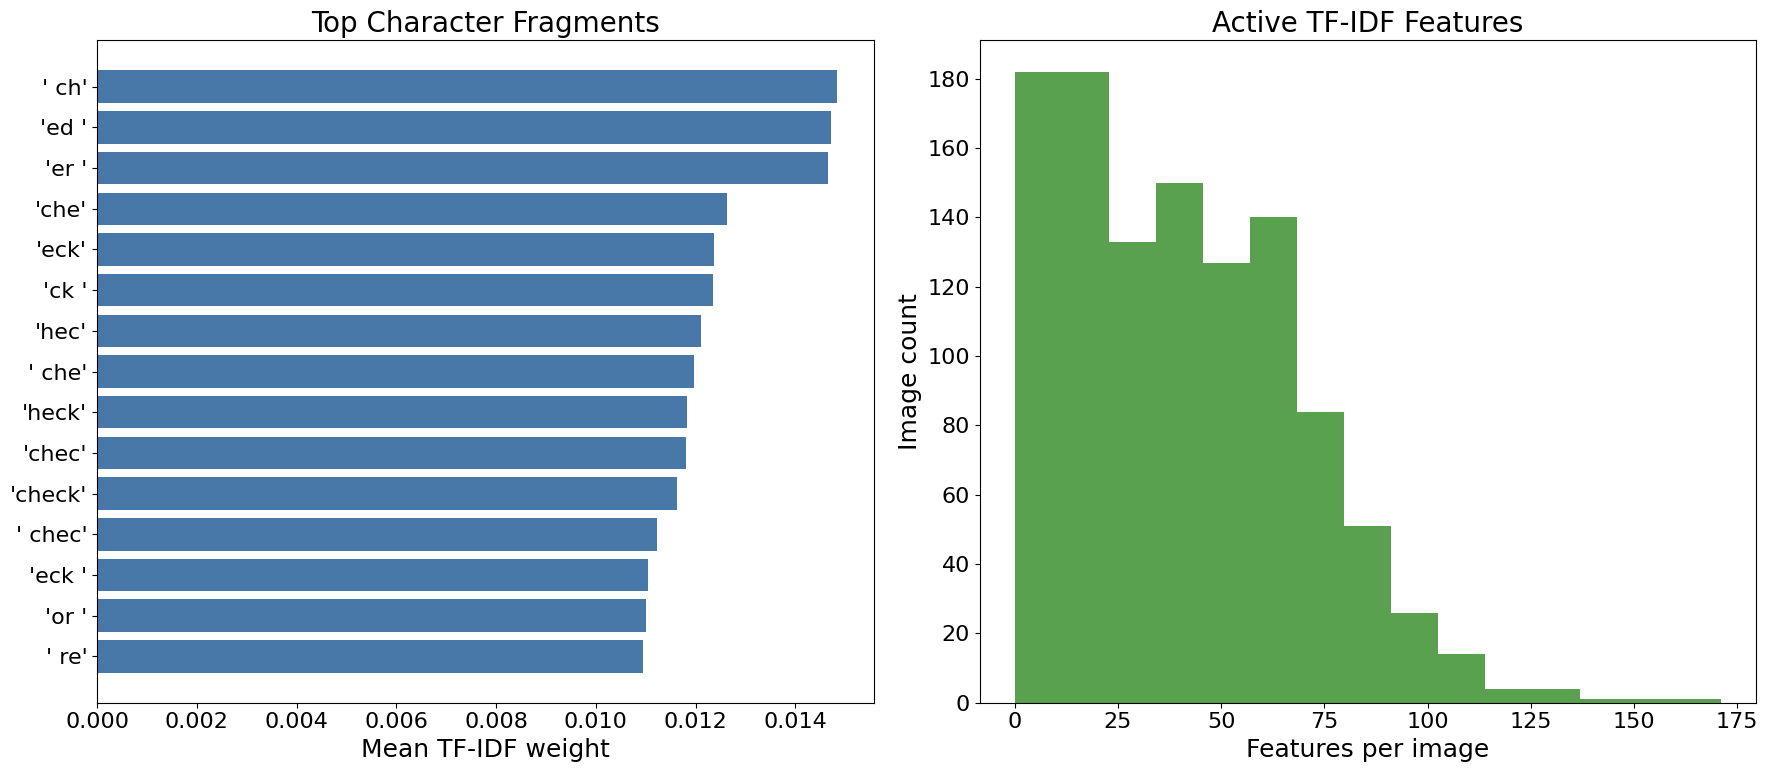

In [111]:
tfidf_summary = pd.DataFrame(
    {
        "images": [tfidf_embeddings.shape[0]],
        "features": [tfidf_embeddings.shape[1]],
        "nonzero_values": [tfidf_embeddings.nnz],
        "sparsity_percent": [
            (1 - tfidf_embeddings.nnz / np.prod(tfidf_embeddings.shape)) * 100
        ],
        "zero_vectors": [
            np.count_nonzero(tfidf_embeddings.getnnz(axis=1) == 0)
        ],
    },
    index=["TF-IDF"],
)
tfidf_features = pd.DataFrame(
    {
        "feature_index": np.arange(tfidf_embeddings.shape[1]),
        "character_fragment": tfidf_vectorizer.get_feature_names_out(),
        "idf": tfidf_vectorizer.idf_,
        "mean_tfidf": np.asarray(tfidf_embeddings.mean(axis=0)).ravel(),
    }
)
top_features = tfidf_features.nlargest(15, "mean_tfidf")
preview_features = top_features["feature_index"].head(8).to_numpy()

display(tfidf_summary)
display(top_features)
display(embedding_metadata.head())
display(
    pd.DataFrame(
        tfidf_embeddings[:5, preview_features].toarray(),
        index=embedding_metadata["file_name"].head(5),
        columns=tfidf_vectorizer.get_feature_names_out()[preview_features],
    )
)
tfidf_summary.to_csv(TFIDF_RESULTS_DIR / "tfidf_summary.csv", index=False)
tfidf_features.to_csv(TFIDF_RESULTS_DIR / "tfidf_features.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
axes[0].barh(
    [repr(fragment) for fragment in top_features["character_fragment"]],
    top_features["mean_tfidf"],
    color="#4878A8",
)
axes[0].invert_yaxis()
axes[0].set(title="Top Character Fragments", xlabel="Mean TF-IDF weight")
axes[0].xaxis.set_major_formatter(StrMethodFormatter("{x:,.3f}"))
axes[1].hist(tfidf_embeddings.getnnz(axis=1), bins=15, color="#59A14F")
axes[1].set(
    title="Active TF-IDF Features",
    xlabel="Features per image",
    ylabel="Image count",
)
axes[1].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
fig.tight_layout()
fig.savefig(
    TFIDF_RESULTS_DIR / "tfidf_statistics.png", dpi=150, bbox_inches="tight"
)
plt.show()

In [112]:
def create_tfidf_pca_projection(embeddings, metadata):
    """Project nonzero sparse TF-IDF vectors onto two principal components.

    Args:
        embeddings (scipy.sparse.csr_matrix): TF-IDF vectors in image row order.
        metadata (pd.DataFrame): Corresponding image metadata and labels.

    Returns:
        tuple: Image metadata with pc1 and pc2 coordinates, and the fitted PCA.

    Raises:
        ValueError: If fewer than three nonzero vectors or features are available.
    """
    has_features = embeddings.getnnz(axis=1) > 0
    nonzero_embeddings = embeddings[has_features]
    if min(nonzero_embeddings.shape) <= 2:
        raise ValueError(
            "ARPACK PCA needs at least three nonzero images and features."
        )

    pca = PCA(n_components=2, svd_solver="arpack", random_state=42)
    coordinates = pca.fit_transform(nonzero_embeddings)
    projection = metadata.loc[has_features].copy()
    projection[["pc1", "pc2"]] = coordinates
    return projection, pca

In [113]:
tfidf_projection, tfidf_pca = create_tfidf_pca_projection(
    tfidf_embeddings, embedding_metadata
)

Images in PCA projection: 1,075


,component,explained_variance_percent
0,PC1,1.57
1,PC2,1.50


,file_name,label,pc1,pc2
0,0000a.jpg,alcohol,0.01,0.12
1,0001a.jpg,alcohol,-0.02,-0.07
2,0003a.jpg,alcohol,-0.05,-0.05
3,0004a.jpg,alcohol,-0.05,-0.06
4,0005a.jpg,alcohol,0.07,0.32


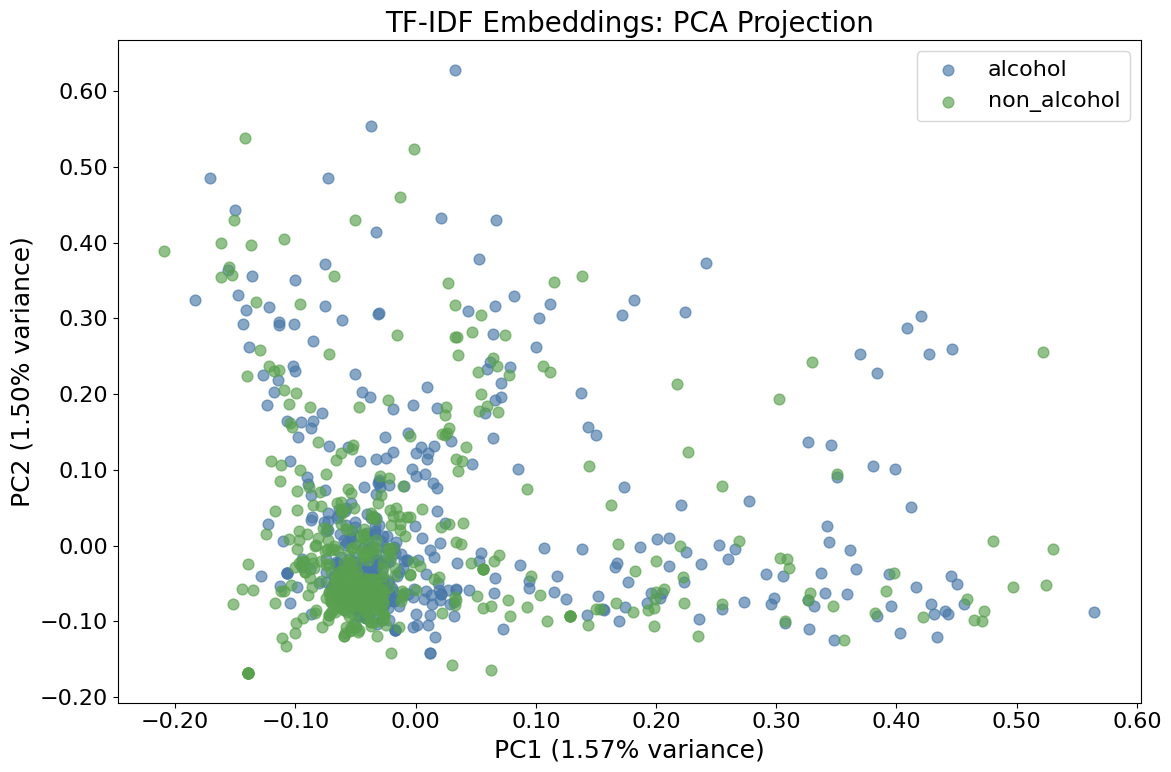

In [114]:
tfidf_pca_summary = pd.DataFrame(
    {
        "component": ["PC1", "PC2"],
        "explained_variance_percent": tfidf_pca.explained_variance_ratio_ * 100,
    }
)
print(f"Images in PCA projection: {len(tfidf_projection):,}")
display(tfidf_pca_summary)
display(tfidf_projection[["file_name", "label", "pc1", "pc2"]].head())
tfidf_projection.to_csv(TFIDF_RESULTS_DIR / "tfidf_pca.csv", index=False)
tfidf_pca_summary.to_csv(
    TFIDF_RESULTS_DIR / "tfidf_pca_summary.csv", index=False
)

fig, axis = plt.subplots(figsize=(12, 8))
for label, color in (("alcohol", "#4878A8"), ("non_alcohol", "#59A14F")):
    points = tfidf_projection.loc[tfidf_projection["label"].eq(label)]
    axis.scatter(
        points["pc1"],
        points["pc2"],
        label=label,
        color=color,
        s=60,
        alpha=0.65,
    )
axis.set(
    title="TF-IDF Embeddings: PCA Projection",
    xlabel=f"PC1 ({tfidf_pca.explained_variance_ratio_[0] * 100:,.2f}% variance)",
    ylabel=f"PC2 ({tfidf_pca.explained_variance_ratio_[1] * 100:,.2f}% variance)",
)
axis.xaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
axis.yaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
axis.legend()
fig.tight_layout()
fig.savefig(TFIDF_RESULTS_DIR / "tfidf_pca.png", dpi=150, bbox_inches="tight")
plt.show()

## Bert-Based

Use [all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2), a pretrained sentence encoder that returns 384-dimensional vectors. Run on the CPU in batches and L2-normalize nonempty text embeddings. Set empty-text embeddings to zero so they indicate missing OCR evidence.

First run downloads model files into `.cache/sentence_transformers/`, later runs reuse them.
Inputs longer than the model's token limit are truncated, so report their count below.

In [115]:
def create_bert_embeddings(texts, model, batch_size=32):
    """Encode nonempty OCR text and preserve zero vectors for empty text.

    Args:
        texts (pd.Series): OCR text with missing values replaced by strings.
        model (SentenceTransformer): Initialized CPU sentence encoder.
        batch_size (int): Number of texts to encode in each batch.

    Returns:
        np.ndarray: Float32 feature matrix in input row order. Nonempty
            vectors have unit L2 norm; empty text has an all-zero vector.
    """
    embeddings = np.zeros(
        (len(texts), model.get_sentence_embedding_dimension()), dtype=np.float32
    )
    has_text = texts.str.strip().ne("").to_numpy()
    if has_text.any():
        embeddings[has_text] = model.encode(
            texts.loc[has_text].tolist(),
            batch_size=batch_size,
            show_progress_bar=True,
            convert_to_numpy=True,
            normalize_embeddings=True,
        )
    return embeddings

In [116]:
bert_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    revision="1110a243fdf4706b3f48f1d95db1a4f5529b4d41",
    device="cpu",
    cache_folder=str(Path(".cache") / "sentence_transformers"),
)
bert_embeddings = create_bert_embeddings(embedding_texts, bert_model)
np.save(BERT_RESULTS_DIR / "bert_embeddings.npy", bert_embeddings)

Batches:   0%|          | 0/34 [00:00<?, ?it/s]

,images,dimensions,zero_vectors,max_tokens,truncated_texts
MiniLM,1100,384,22,256,0


,image_count,images_with_text,mean_token_count,truncated_texts
label,,,,
alcohol,550,537,10.52,0
non_alcohol,550,541,10.83,0


,file_name,label,token_count,vector_norm
0,0000a.jpg,alcohol,15,1.00
1,0001a.jpg,alcohol,6,1.00
2,0003a.jpg,alcohol,21,1.00
3,0004a.jpg,alcohol,13,1.00
4,0005a.jpg,alcohol,15,1.00


,dimension_0,dimension_1,dimension_2,dimension_3,dimension_4,dimension_5,dimension_6,dimension_7
file_name,,,,,,,,
0000a.jpg,-0.00,-0.01,0.06,-0.06,-0.03,0.02,0.12,0.03
0001a.jpg,-0.04,-0.03,-0.07,0.01,-0.00,0.00,0.07,0.05
0003a.jpg,-0.08,0.05,0.03,-0.01,-0.00,-0.05,0.16,0.10
0004a.jpg,-0.12,0.09,0.01,-0.05,-0.06,0.00,0.06,0.04
0005a.jpg,-0.05,0.01,0.01,-0.04,-0.01,-0.03,-0.09,0.05


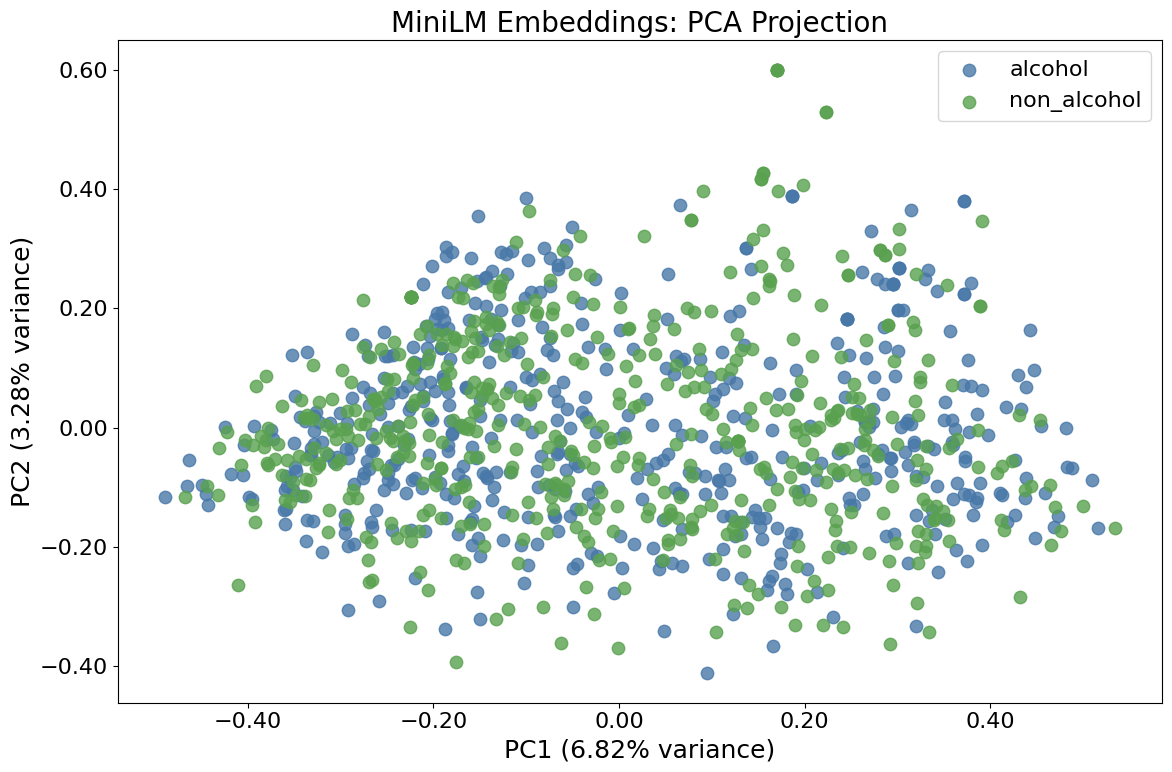

In [117]:
bert_metadata = embedding_metadata.copy()
bert_metadata["token_count"] = bert_model.tokenizer(
    embedding_texts.tolist(), truncation=False, return_length=True
)["length"]
bert_metadata["is_truncated"] = (
    bert_metadata["token_count"] > bert_model.max_seq_length
)
bert_metadata["vector_norm"] = np.linalg.norm(bert_embeddings, axis=1)
bert_summary = pd.DataFrame(
    {
        "images": [bert_embeddings.shape[0]],
        "dimensions": [bert_embeddings.shape[1]],
        "zero_vectors": [np.count_nonzero(bert_metadata["vector_norm"] == 0)],
        "max_tokens": [bert_model.max_seq_length],
        "truncated_texts": [bert_metadata["is_truncated"].sum()],
    },
    index=["MiniLM"],
)
bert_class_summary = bert_metadata.groupby("label").agg(
    image_count=("file_name", "size"),
    images_with_text=("has_text", "sum"),
    mean_token_count=("token_count", "mean"),
    truncated_texts=("is_truncated", "sum"),
)

display(bert_summary)
display(bert_class_summary)
display(
    bert_metadata[["file_name", "label", "token_count", "vector_norm"]].head()
)
display(
    pd.DataFrame(
        bert_embeddings[:5, :8],
        index=embedding_metadata["file_name"].head(5),
        columns=[f"dimension_{index}" for index in range(8)],
    )
)
bert_summary.to_csv(BERT_RESULTS_DIR / "bert_summary.csv", index=False)
bert_class_summary.to_csv(BERT_RESULTS_DIR / "bert_class_summary.csv")
bert_metadata.to_csv(BERT_RESULTS_DIR / "bert_metadata.csv", index=False)

# Exclude missing-text zero vectors from the semantic projection.
has_text = embedding_metadata["has_text"].to_numpy()
if has_text.sum() >= 2:
    pca = PCA(n_components=2, svd_solver="full")
    coordinates = pca.fit_transform(bert_embeddings[has_text])
    projection = embedding_metadata.loc[has_text].copy()
    projection[["pc1", "pc2"]] = coordinates
    projection.to_csv(BERT_RESULTS_DIR / "bert_pca.csv", index=False)

    fig, axis = plt.subplots(figsize=(12, 8))
    for label, color in (("alcohol", "#4878A8"), ("non_alcohol", "#59A14F")):
        points = projection.loc[projection["label"].eq(label)]
        axis.scatter(
            points["pc1"],
            points["pc2"],
            label=label,
            color=color,
            s=80,
            alpha=0.8,
        )
    axis.set(
        title="MiniLM Embeddings: PCA Projection",
        xlabel=f"PC1 ({pca.explained_variance_ratio_[0] * 100:,.2f}% variance)",
        ylabel=f"PC2 ({pca.explained_variance_ratio_[1] * 100:,.2f}% variance)",
    )
    axis.xaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
    axis.yaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
    axis.legend()
    fig.tight_layout()
    fig.savefig(
        BERT_RESULTS_DIR / "bert_pca.png", dpi=150, bbox_inches="tight"
    )
    plt.show()
else:
    print("PCA needs at least two images with extracted text.")

# Classification

Compare Logistic Regression, XGBoost, and Random Forest, each trained once with TF-IDF and once with MiniLM embeddings. All six runs use the same reproducible stratified split: 70% training and 30% held out. `alcohol` is the positive class (1); `non_alcohol` is class 0.

Refit TF-IDF on training text only and transform held-out text with that vectorizer. The earlier full-dataset TF-IDF matrix remains an exploration artifact. Reuse the pretrained BERT embeddings because their encoder was not fitted to this dataset; do not use the exploratory PCA coordinates for classification.

Report per-class precision, recall, F1, and support, plus accuracy, [ROC AUC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html), and [PR AUC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_recall_curve.html). Both AUCs use alcohol probabilities, not predicted labels. PR AUC is the trapezoidal area under the precision–recall curve. Model settings and the 0.5 probability threshold are fixed before evaluation.

In test mode, the 20-image dataset provides only six held-out images. Those results verify the workflow; they are too small for reliable performance conclusions. The comparison does not tune models or select a final production model.

## Utils

In [118]:
def prepare_classification_data(
    texts,
    metadata,
    bert_embeddings,
    tfidf_vectorizer,
    test_size=0.3,
    random_state=42,
):
    """Create a shared held-out split and fit TF-IDF on training text only.

    Args:
        texts (pd.Series): Cleaned OCR text in embedding row order.
        metadata (pd.DataFrame): Image metadata including folder labels.
        bert_embeddings (np.ndarray): Pretrained sentence vectors in row order.
        tfidf_vectorizer (TfidfVectorizer): Template for TF-IDF settings.
        test_size (float): Fraction of images held out for evaluation.
        random_state (int): Seed for a reproducible stratified split.

    Returns:
        dict: Feature splits, training and test labels, test image metadata,
            complete split metadata, and the training-fitted vectorizer.
    """
    metadata = metadata.reset_index(drop=True)
    labels = metadata["label"].map({"non_alcohol": 0, "alcohol": 1}).to_numpy()
    train_indices, test_indices = train_test_split(
        np.arange(len(labels)),
        test_size=test_size,
        stratify=labels,
        random_state=random_state,
    )

    training_vectorizer = clone(tfidf_vectorizer)
    tfidf_train = training_vectorizer.fit_transform(texts.iloc[train_indices])
    tfidf_test = training_vectorizer.transform(texts.iloc[test_indices])
    split_metadata = metadata.copy()
    split_metadata["split"] = "train"
    split_metadata.loc[test_indices, "split"] = "test"

    return {
        "feature_splits": {
            "tfidf": (tfidf_train, tfidf_test),
            "bert": (
                bert_embeddings[train_indices],
                bert_embeddings[test_indices],
            ),
        },
        "y_train": labels[train_indices],
        "y_test": labels[test_indices],
        "test_metadata": metadata.iloc[test_indices].reset_index(drop=True),
        "split_metadata": split_metadata,
        "tfidf_vectorizer": training_vectorizer,
    }


def evaluate_embeddings(classifier, classification_data):
    """Fit separate classifier instances for TF-IDF and BERT and evaluate them.

    Args:
        classifier: Unfitted classifier supporting predict_proba.
        classification_data (dict): Features and labels from the shared split.

    Returns:
        dict: Per-embedding models, classification reports, metrics, held-out
            predictions, alcohol probabilities, and ROC and PR curve points.
    """
    results = {}
    y_train = classification_data["y_train"]
    y_test = classification_data["y_test"]
    for embedding_name, (x_train, x_test) in classification_data[
        "feature_splits"
    ].items():
        model = clone(classifier)
        model.fit(x_train, y_train)
        predictions = model.predict(x_test)
        positive_column = np.flatnonzero(model.classes_ == 1)[0]
        probabilities = model.predict_proba(x_test)[:, positive_column]
        report_values = classification_report(
            y_test,
            predictions,
            labels=[0, 1],
            target_names=["non_alcohol", "alcohol"],
            output_dict=True,
            zero_division=0,
        )
        accuracy = report_values.pop("accuracy")
        report = pd.DataFrame(report_values).T
        report.index.name = "class"
        fpr, tpr, _ = roc_curve(y_test, probabilities, pos_label=1)
        precision, recall, _ = precision_recall_curve(
            y_test, probabilities, pos_label=1
        )
        results[embedding_name] = {
            "model": model,
            "report": report,
            "metrics": {
                "train_images": len(y_train),
                "test_images": len(y_test),
                "accuracy": accuracy,
                "precision": report_values["alcohol"]["precision"],
                "recall": report_values["alcohol"]["recall"],
                "f1": report_values["alcohol"]["f1-score"],
                "macro_f1": report_values["macro avg"]["f1-score"],
                "roc_auc": roc_auc_score(y_test, probabilities),
                "pr_auc": auc(recall, precision),
            },
            "predictions": predictions,
            "probabilities": probabilities,
            "roc_curve": pd.DataFrame({"fpr": fpr, "tpr": tpr}),
            "pr_curve": pd.DataFrame(
                {"recall": recall, "precision": precision}
            ),
        }
    return results


def show_classifier_results(
    classifier_name, results, classification_data, output_dir
):
    """Display and save reports, predictions, models, and probability curves.

    Args:
        classifier_name (str): Name displayed in tables and plots.
        results (dict): Per-embedding output from evaluate_embeddings.
        classification_data (dict): Shared split with held-out image metadata.
        output_dir (Path): Classifier results directory.

    Returns:
        pd.DataFrame: Comparison metrics for the classifier's two embeddings.
    """
    summary_rows = []
    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    for embedding_name, result in results.items():
        embedding_dir = output_dir / embedding_name
        embedding_dir.mkdir(parents=True, exist_ok=True)
        metrics = result["metrics"]
        summary_rows.append(
            {
                "classifier": classifier_name,
                "embedding": embedding_name,
                **metrics,
            }
        )
        print(f"{classifier_name} | {embedding_name.upper()}")
        display(
            result["report"].style.format(
                {
                    "precision": "{:,.3f}",
                    "recall": "{:,.3f}",
                    "f1-score": "{:,.3f}",
                    "support": "{:,.0f}",
                }
            )
        )
        print(
            f"ROC AUC: {metrics['roc_auc']:,.3f} | PR AUC: {metrics['pr_auc']:,.3f}"
        )
        result["report"].to_csv(embedding_dir / "classification_report.csv")
        pd.DataFrame([metrics]).to_csv(
            embedding_dir / "metrics.csv", index=False
        )
        result["roc_curve"].to_csv(embedding_dir / "roc_curve.csv", index=False)
        result["pr_curve"].to_csv(embedding_dir / "pr_curve.csv", index=False)
        joblib.dump(result["model"], embedding_dir / "classifier.joblib")

        predictions = classification_data["test_metadata"].copy()
        predictions["prediction"] = np.where(
            result["predictions"] == 1, "alcohol", "non_alcohol"
        )
        predictions["alcohol_probability"] = result["probabilities"]
        predictions["is_correct"] = predictions["prediction"].eq(
            predictions["label"]
        )
        predictions.to_csv(embedding_dir / "test_predictions.csv", index=False)

        roc_points = result["roc_curve"]
        pr_points = result["pr_curve"]
        axes[0].plot(
            roc_points["fpr"],
            roc_points["tpr"],
            linewidth=2.5,
            label=f"{embedding_name.upper()} (AUC={metrics['roc_auc']:,.3f})",
        )
        axes[1].plot(
            pr_points["recall"],
            pr_points["precision"],
            linewidth=2.5,
            label=f"{embedding_name.upper()} (AUC={metrics['pr_auc']:,.3f})",
        )

    axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Chance")
    prevalence = classification_data["y_test"].mean()
    axes[1].axhline(
        prevalence,
        linestyle="--",
        color="gray",
        label=f"Prevalence ({prevalence:,.2f})",
    )
    axes[0].set(
        title=f"{classifier_name}: ROC",
        xlabel="False positive rate",
        ylabel="True positive rate",
    )
    axes[1].set(
        title=f"{classifier_name}: Precision–Recall",
        xlabel="Recall",
        ylabel="Precision",
    )
    for axis in axes:
        axis.set(xlim=(0, 1), ylim=(0, 1.05))
        axis.xaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
        axis.yaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
        axis.legend(fontsize=13, loc="lower right")
    fig.tight_layout()
    fig.savefig(output_dir / "roc_pr_curves.png", dpi=150, bbox_inches="tight")
    plt.show()
    summary = pd.DataFrame(summary_rows)
    summary.to_csv(output_dir / "metrics_summary.csv", index=False)
    display(summary)
    return summary

## Preparations

In [119]:
CLASSIFICATION_RESULTS_DIR = RESULTS_DIR / "classification"
CLASSIFICATION_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
classification_data = prepare_classification_data(
    embedding_texts, embedding_metadata, bert_embeddings, tfidf_vectorizer
)
classification_data["split_metadata"].to_csv(
    CLASSIFICATION_RESULTS_DIR / "data_split.csv", index=False
)
joblib.dump(
    classification_data["tfidf_vectorizer"],
    CLASSIFICATION_RESULTS_DIR / "tfidf_training_vectorizer.joblib",
)

['results/classification/tfidf_training_vectorizer.joblib']

In [120]:
split_summary = (
    classification_data["split_metadata"]
    .groupby(["split", "label"])
    .size()
    .unstack(fill_value=0)
)
print(f"Training images: {len(classification_data['y_train']):,}")
print(f"Held-out images: {len(classification_data['y_test']):,}")
if test_mode:
    print("Test mode: these metrics are workflow checks on a small dataset.")
display(split_summary)
split_summary.to_csv(CLASSIFICATION_RESULTS_DIR / "split_summary.csv")

Training images: 770
Held-out images: 330


label,alcohol,non_alcohol
split,,
test,165,165
train,385,385


## Logistic Regression

A linear baseline for normalized sparse TF-IDF and dense MiniLM features. Use the same settings for both representations, with up to 1,000 iterations.

In [121]:
def run_logistic_regression(classification_data):
    """Train and evaluate Logistic Regression once per embedding type.

    Args:
        classification_data (dict): Shared feature splits and labels.

    Returns:
        dict: TF-IDF and BERT evaluation results.
    """
    classifier = LogisticRegression(max_iter=1000, random_state=42)
    return evaluate_embeddings(classifier, classification_data)

In [122]:
logistic_results = run_logistic_regression(classification_data)

Logistic Regression | TFIDF


,precision,recall,f1-score,support
class,,,,
non_alcohol,0.929,0.867,0.897,165
alcohol,0.875,0.933,0.903,165
macro avg,0.902,0.900,0.900,330
weighted avg,0.902,0.900,0.900,330


ROC AUC: 0.971 | PR AUC: 0.972
Logistic Regression | BERT


,precision,recall,f1-score,support
class,,,,
non_alcohol,0.812,0.788,0.800,165
alcohol,0.794,0.818,0.806,165
macro avg,0.803,0.803,0.803,330
weighted avg,0.803,0.803,0.803,330


ROC AUC: 0.877 | PR AUC: 0.873


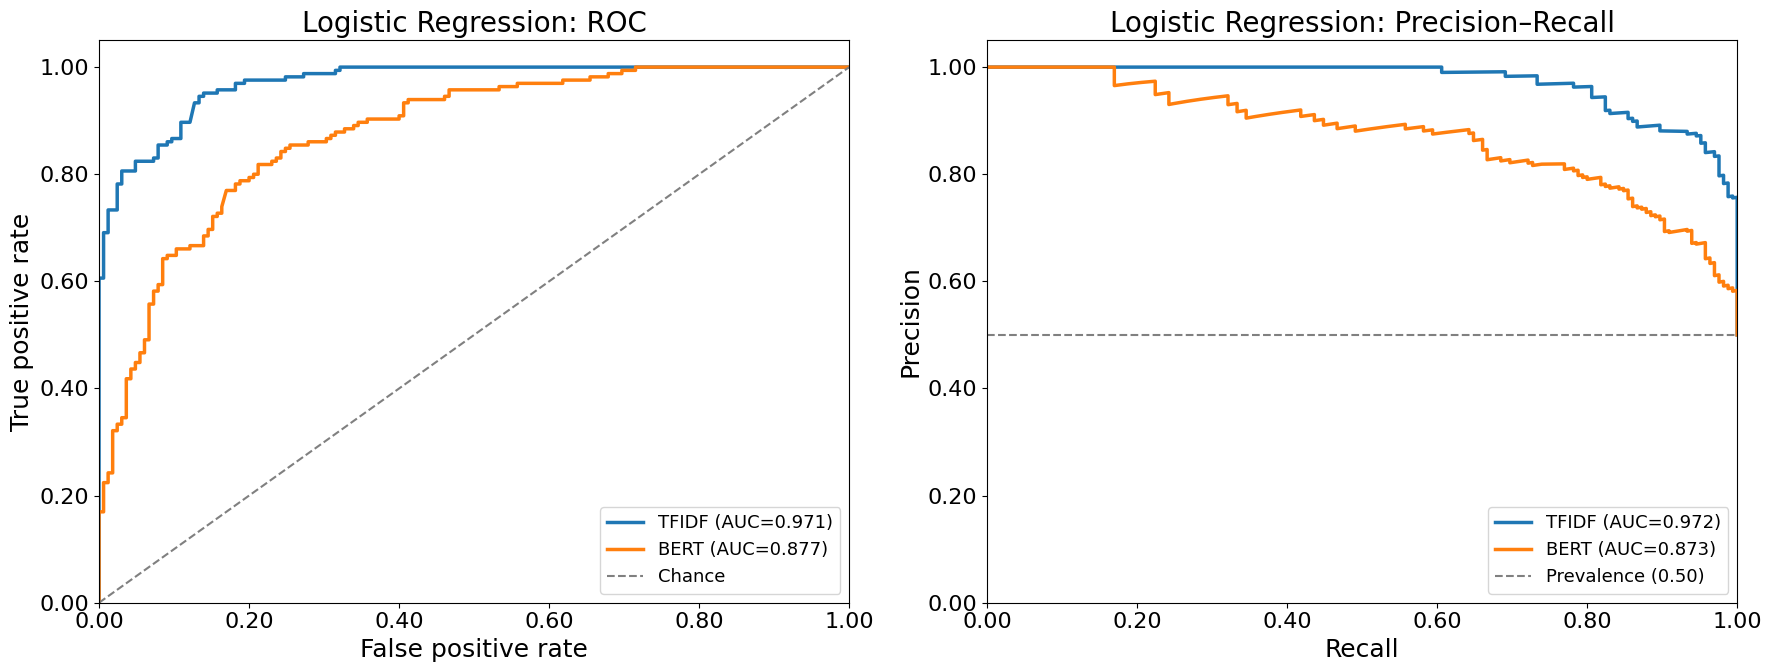

,classifier,embedding,train_images,test_images,accuracy,precision,recall,f1,macro_f1,roc_auc,pr_auc
0,Logistic Regression,tfidf,770,330,0.90,0.88,0.93,0.90,0.90,0.97,0.97
1,Logistic Regression,bert,770,330,0.80,0.79,0.82,0.81,0.80,0.88,0.87


In [123]:
logistic_summary = show_classifier_results(
    "Logistic Regression",
    logistic_results,
    classification_data,
    CLASSIFICATION_RESULTS_DIR / "logistic_regression",
)

## XGBoost

Use 200 shallow boosted trees with depth 3 and learning rate 0.05. The histogram algorithm runs on the CPU; settings stay identical across embeddings and are not tuned on held-out data.

In [124]:
def run_xgboost(classification_data):
    """Train and evaluate CPU XGBoost once per embedding type.

    Args:
        classification_data (dict): Shared feature splits and labels.

    Returns:
        dict: TF-IDF and BERT evaluation results.
    """
    classifier = XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        device="cpu",
        n_jobs=4,
        random_state=42,
    )
    return evaluate_embeddings(classifier, classification_data)

In [125]:
xgboost_results = run_xgboost(classification_data)

XGBoost | TFIDF


,precision,recall,f1-score,support
class,,,,
non_alcohol,0.951,0.703,0.808,165
alcohol,0.764,0.964,0.853,165
macro avg,0.858,0.833,0.830,330
weighted avg,0.858,0.833,0.830,330


ROC AUC: 0.935 | PR AUC: 0.938
XGBoost | BERT


,precision,recall,f1-score,support
class,,,,
non_alcohol,0.765,0.752,0.758,165
alcohol,0.756,0.770,0.763,165
macro avg,0.761,0.761,0.761,330
weighted avg,0.761,0.761,0.761,330


ROC AUC: 0.839 | PR AUC: 0.843


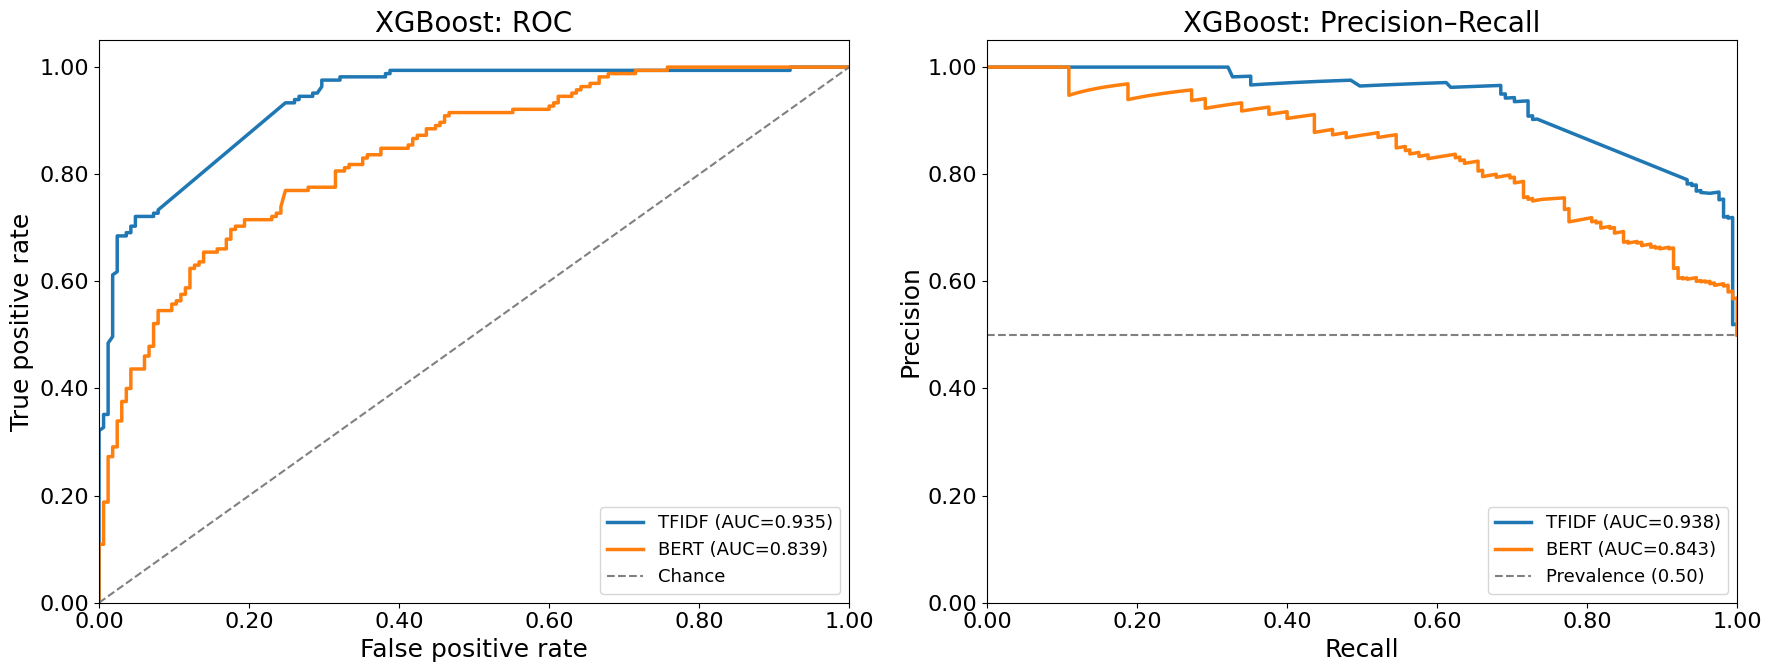

,classifier,embedding,train_images,test_images,accuracy,precision,recall,f1,macro_f1,roc_auc,pr_auc
0,XGBoost,tfidf,770,330,0.83,0.76,0.96,0.85,0.83,0.93,0.94
1,XGBoost,bert,770,330,0.76,0.76,0.77,0.76,0.76,0.84,0.84


In [126]:
xgboost_summary = show_classifier_results(
    "XGBoost",
    xgboost_results,
    classification_data,
    CLASSIFICATION_RESULTS_DIR / "xgboost",
)

## Random Forest

Use 200 bagged trees with at least two training images per leaf. Keep the random seed and settings fixed for both embedding types.

In [127]:
def run_random_forest(classification_data):
    """Train and evaluate Random Forest once per embedding type.

    Args:
        classification_data (dict): Shared feature splits and labels.

    Returns:
        dict: TF-IDF and BERT evaluation results.
    """
    classifier = RandomForestClassifier(
        n_estimators=200, min_samples_leaf=2, n_jobs=4, random_state=42
    )
    return evaluate_embeddings(classifier, classification_data)

In [128]:
random_forest_results = run_random_forest(classification_data)

Random Forest | TFIDF


,precision,recall,f1-score,support
class,,,,
non_alcohol,0.922,0.788,0.850,165
alcohol,0.815,0.933,0.870,165
macro avg,0.868,0.861,0.860,330
weighted avg,0.868,0.861,0.860,330


ROC AUC: 0.950 | PR AUC: 0.953
Random Forest | BERT


,precision,recall,f1-score,support
class,,,,
non_alcohol,0.768,0.782,0.775,165
alcohol,0.778,0.764,0.771,165
macro avg,0.773,0.773,0.773,330
weighted avg,0.773,0.773,0.773,330


ROC AUC: 0.871 | PR AUC: 0.876


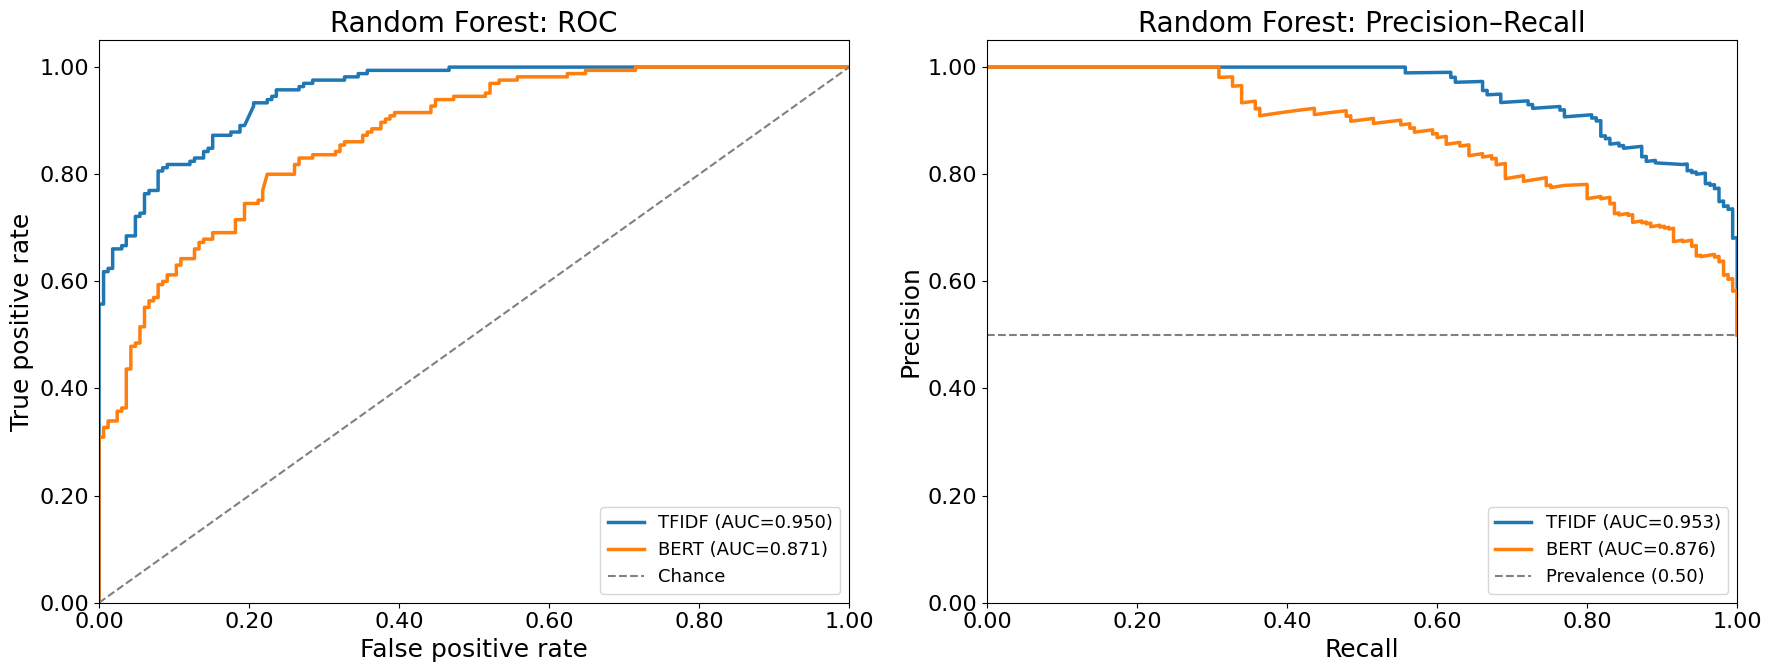

,classifier,embedding,train_images,test_images,accuracy,precision,recall,f1,macro_f1,roc_auc,pr_auc
0,Random Forest,tfidf,770,330,0.86,0.81,0.93,0.87,0.86,0.95,0.95
1,Random Forest,bert,770,330,0.77,0.78,0.76,0.77,0.77,0.87,0.88


In [129]:
random_forest_summary = show_classifier_results(
    "Random Forest",
    random_forest_results,
    classification_data,
    CLASSIFICATION_RESULTS_DIR / "random_forest",
)

## Performance Comparison

Compare all six runs on the same held-out images. Precision, recall, and F1 below refer to `alcohol`; macro F1 gives both classes equal weight. The per-class reports remain available in each classifier's TF-IDF and BERT subfolders.

In [130]:
def compare_classifiers(summaries):
    """Combine classifier summaries into one comparison table.

    Args:
        summaries (list[pd.DataFrame]): Per-classifier embedding summaries.

    Returns:
        pd.DataFrame: All classifier and embedding metrics, sorted by PR AUC
            and then ROC AUC for display.
    """
    return (
        pd.concat(summaries, ignore_index=True)
        .sort_values(["pr_auc", "roc_auc"], ascending=False)
        .reset_index(drop=True)
    )

In [131]:
performance_comparison = compare_classifiers(
    [logistic_summary, xgboost_summary, random_forest_summary]
)

,classifier,embedding,train_images,test_images,accuracy,precision,recall,f1,macro_f1,roc_auc,pr_auc
0,Logistic Regression,tfidf,770,330,0.900,0.875,0.933,0.903,0.900,0.971,0.972
1,Random Forest,tfidf,770,330,0.861,0.815,0.933,0.870,0.860,0.950,0.953
2,XGBoost,tfidf,770,330,0.833,0.764,0.964,0.853,0.830,0.935,0.938
3,Random Forest,bert,770,330,0.773,0.778,0.764,0.771,0.773,0.871,0.876
4,Logistic Regression,bert,770,330,0.803,0.794,0.818,0.806,0.803,0.877,0.873
5,XGBoost,bert,770,330,0.761,0.756,0.770,0.763,0.761,0.839,0.843


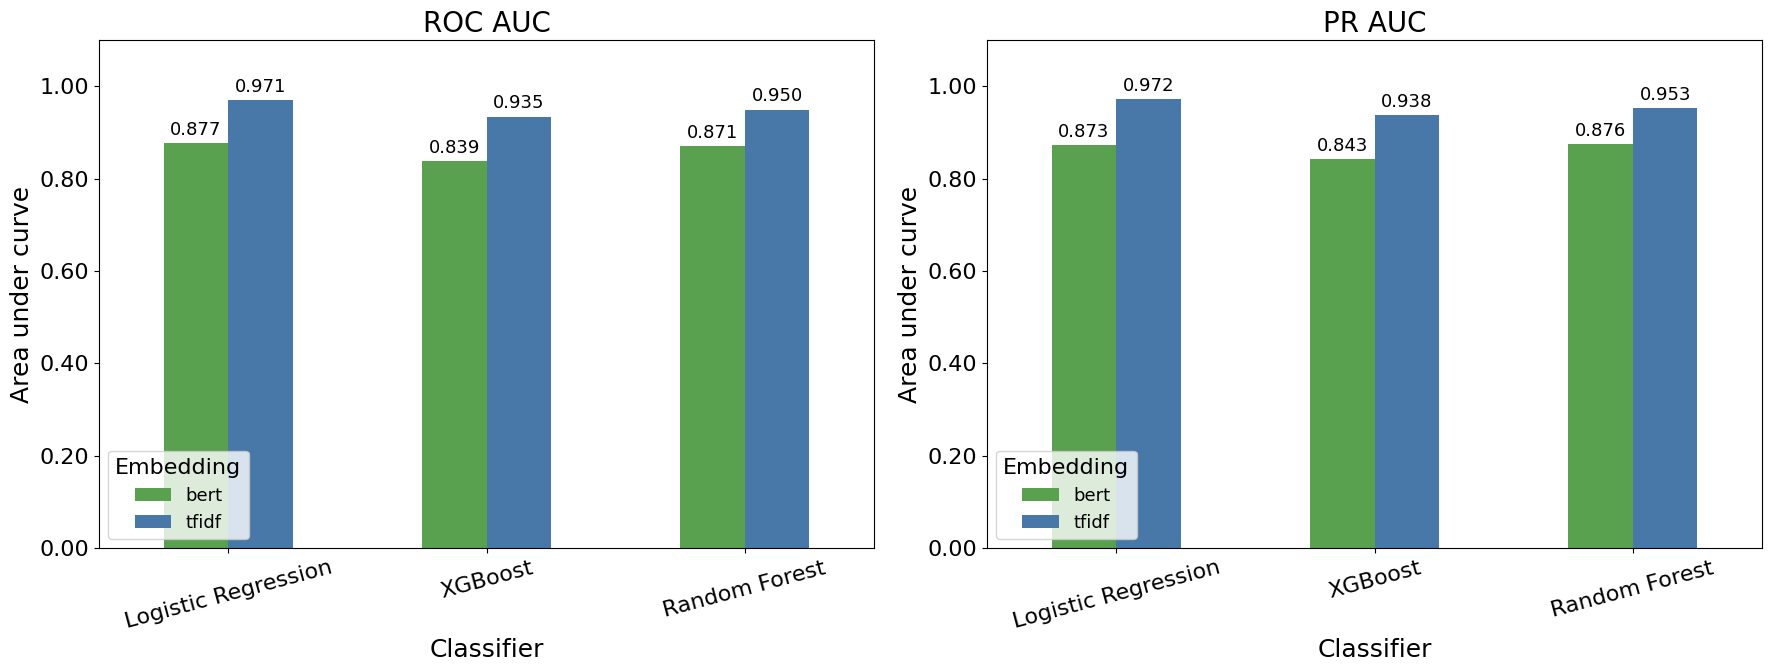

In [132]:
display(
    performance_comparison.style.format(
        {
            column: "{:,.3f}"
            for column in [
                "accuracy",
                "precision",
                "recall",
                "f1",
                "macro_f1",
                "roc_auc",
                "pr_auc",
            ]
        }
        | {"train_images": "{:,.0f}", "test_images": "{:,.0f}"}
    )
)
performance_comparison.to_csv(
    CLASSIFICATION_RESULTS_DIR / "performance_comparison.csv", index=False
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for axis, metric, title in zip(
    axes, ["roc_auc", "pr_auc"], ["ROC AUC", "PR AUC"]
):
    comparison_plot = performance_comparison.pivot(
        index="classifier", columns="embedding", values=metric
    ).reindex(["Logistic Regression", "XGBoost", "Random Forest"])
    comparison_plot.plot.bar(ax=axis, rot=15, color=["#59A14F", "#4878A8"])
    axis.set(
        title=title,
        xlabel="Classifier",
        ylabel="Area under curve",
        ylim=(0, 1.1),
    )
    axis.yaxis.set_major_formatter(StrMethodFormatter("{x:,.2f}"))
    axis.legend(title="Embedding", fontsize=13)
    for container in axis.containers:
        axis.bar_label(container, fmt="{:,.3f}", padding=3, fontsize=13)
fig.tight_layout()
fig.savefig(
    CLASSIFICATION_RESULTS_DIR / "performance_comparison.png",
    dpi=150,
    bbox_inches="tight",
)
plt.show()